In [1]:
# %%  # Cell 1: Config - edit these variables in the notebook before running the training cells
# Notebook-friendly configuration: edit values below instead of using argparse in a script.
config = {}  # create an empty dict to hold all training configuration

config["tiles_root"] = "/home/ehr/Desktop/anupama/plant/class_tiles"  # path to dataset root containing train/val folders
config["out_dir"] = "/home/ehr/Desktop/anupama/plant/training_runs"  # output folder for models and logs
config["model_name"] = "resnet34"  # which backbone to use: resnet18/resnet34/resnet50/efficientnet_b0
config["epochs"] = 30  # total number of training epochs
config["batch_size"] = 32  # batch size for train and val loaders
config["lr"] = 3e-4  # learning rate for optimizer
config["weight_decay"] = 1e-4  # weight decay (L2) for optimizer
config["img_size"] = 224  # input image size (square)
config["num_workers"] = 4  # DataLoader workers (set 0 on Windows / notebook issues)
config["seed"] = 42  # random seed for reproducibility

config["use_weighted_sampler"] = True  # whether to use WeightedRandomSampler for class balancing
config["use_class_weights"] = True  # whether to pass class weights to CrossEntropyLoss
config["weight_power"] = 0.5  # exponent for softened class weights
config["max_weight"] = 20.0  # cap for maximum class weight

config["label_smoothing"] = 0.05  # label smoothing for CrossEntropyLoss
config["pretrained"] = True  # whether to use pretrained weights for backbone
config["freeze_epochs"] = 2  # freeze backbone for this many initial epochs

config["use_mixup"] = False  # whether to enable MixUp augmentation in training
config["mixup_alpha"] = 0.2  # alpha parameter for MixUp beta distribution

config["scheduler"] = "onecycle"  # learning rate scheduler: onecycle / cosine / none
config["grad_clip"] = 1.0  # gradient clipping max norm (0 or None to disable)

config["save_best_by"] = "macro_f1"  # metric to decide best model: macro_f1 or val_acc
config["early_stop_patience"] = 6  # early stopping patience in epochs

# quick display of the configuration so you can verify before running
from pprint import pprint  # import pprint to print dictionary nicely
pprint(config)  # print the full config for inspection


{'batch_size': 32,
 'early_stop_patience': 6,
 'epochs': 30,
 'freeze_epochs': 2,
 'grad_clip': 1.0,
 'img_size': 224,
 'label_smoothing': 0.05,
 'lr': 0.0003,
 'max_weight': 20.0,
 'mixup_alpha': 0.2,
 'model_name': 'resnet34',
 'num_workers': 4,
 'out_dir': '/home/ehr/Desktop/anupama/plant/training_runs',
 'pretrained': True,
 'save_best_by': 'macro_f1',
 'scheduler': 'onecycle',
 'seed': 42,
 'tiles_root': '/home/ehr/Desktop/anupama/plant/class_tiles',
 'use_class_weights': True,
 'use_mixup': False,
 'use_weighted_sampler': True,
 'weight_decay': 0.0001,
 'weight_power': 0.5}


In [2]:
import os
from pprint import pprint

config = {}

config["tiles_root"] = "/home/ehr/Desktop/anupama/plant/class_tiles"
config["out_dir"] = "/home/ehr/Desktop/anupama/plant/training_runs"
config["model_name"] = "resnet34"
config["epochs"] = 30
config["batch_size"] = 32
config["lr"] = 3e-4
config["weight_decay"] = 1e-4
config["img_size"] = 224
config["num_workers"] = 4
config["seed"] = 42

config["use_weighted_sampler"] = True
config["use_class_weights"] = True
config["weight_power"] = 0.5
config["max_weight"] = 20.0

config["label_smoothing"] = 0.05
config["pretrained"] = True
config["freeze_epochs"] = 2

config["use_mixup"] = False
config["mixup_alpha"] = 0.2

config["scheduler"] = "onecycle"
config["grad_clip"] = 1.0

config["save_best_by"] = "macro_f1"
config["early_stop_patience"] = 6

os.makedirs(config["out_dir"], exist_ok=True)

pprint(config)

{'batch_size': 32,
 'early_stop_patience': 6,
 'epochs': 30,
 'freeze_epochs': 2,
 'grad_clip': 1.0,
 'img_size': 224,
 'label_smoothing': 0.05,
 'lr': 0.0003,
 'max_weight': 20.0,
 'mixup_alpha': 0.2,
 'model_name': 'resnet34',
 'num_workers': 4,
 'out_dir': '/home/ehr/Desktop/anupama/plant/training_runs',
 'pretrained': True,
 'save_best_by': 'macro_f1',
 'scheduler': 'onecycle',
 'seed': 42,
 'tiles_root': '/home/ehr/Desktop/anupama/plant/class_tiles',
 'use_class_weights': True,
 'use_mixup': False,
 'use_weighted_sampler': True,
 'weight_decay': 0.0001,
 'weight_power': 0.5}


In [3]:
# %%  # Cell 2: Imports and constants
# standard library imports
import json  # for saving history to JSON
from pathlib import Path  # path convenience
from dataclasses import dataclass  # for EpochMetrics dataclass (optional)
from typing import Dict, List, Tuple, Optional  # typing hints

# third-party imports
import numpy as np  # numeric operations
from PIL import Image  # image loading

import torch  # core PyTorch
import torch.nn as nn  # neural net modules
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler  # data utilities
from torchvision import transforms  # image transforms
from torchvision.models import (  # model constructors and weight enums
    resnet18, resnet34, resnet50, ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

# try to import sklearn metrics - optional but preferred for f1/class report
try:
    from sklearn.metrics import confusion_matrix, classification_report, f1_score
    SKLEARN_OK = True  # flag if sklearn is available
except Exception:
    SKLEARN_OK = False  # otherwise fallback to NaN for macro_f1

# dataset constants (same classes as original script)
CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}  # map class name -> id



In [ ]:
import torch
print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("cuda device count:", torch.cuda.device_count())
print("cuda version in torch:", torch.version.cuda)

torch version: 2.9.1+cu128
cuda available: True
cuda device count: 1
cuda version in torch: 12.8


In [4]:
# %%  # Cell 3: Utility functions and Dataset class
# helper to check typical image file suffixes
def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}  # true if known image

# custom Dataset reading tiles from class-labeled folders
class TileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None):
        self.tiles_root = Path(tiles_root)  # store the root path
        self.split = split  # which split: "train" or "val"
        self.transform = transform  # torchvision transform pipeline

        split_dir = self.tiles_root / split  # path to split directory
        if not split_dir.exists():  # ensure split folder exists
            raise FileNotFoundError(f"Split folder not found: {split_dir}")  # helpful error

        items: List[Tuple[Path, int]] = []  # list to accumulate (path, label) tuples
        for cls_name in CLASS_NAMES:  # iterate through expected class names
            cls_dir = split_dir / cls_name  # folder for that class
            if not cls_dir.exists():  # warn if class folder missing
                print(f"WARNING: class folder missing: {cls_dir}")
                continue  # skip missing classes

            for img_path in sorted(cls_dir.rglob("*")):  # recursively find files
                if img_path.is_file() and is_image_file(img_path):  # check it's an image file
                    items.append((img_path, CLASS_TO_ID[cls_name]))  # append path and label id

        if len(items) == 0:  # ensure the dataset is not empty
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items  # store the items list

    def __len__(self):
        return len(self.items)  # dataset length

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]  # get tuple
        with Image.open(img_path) as im:  # open image using PIL
            im = im.convert("RGB")  # ensure 3 channels
            if self.transform is not None:  # apply transforms if provided
                im = self.transform(im)
        return im, label  # return tensor (if transform includes ToTensor) and integer label

# small dataclass for epoch-level metrics (optional usage)
@dataclass
class EpochMetrics:
    epoch: int
    train_loss: float
    train_acc: float
    val_loss: float
    val_acc: float
    macro_f1: float


In [5]:
# %%  # Cell 4: Reproducibility, counts, and class-weight helpers
def set_seed(seed: int = 42):
    import random  # local import for reproducibility
    random.seed(seed)  # seed python RNG
    np.random.seed(seed)  # seed numpy RNG
    torch.manual_seed(seed)  # seed CPU torch RNG
    torch.cuda.manual_seed_all(seed)  # seed all CUDA devices

def ensure_split_exists(tiles_root: Path, split: str):
    split_dir = Path(tiles_root) / split  # construct split path
    if not split_dir.exists():  # if missing, raise descriptive error
        raise FileNotFoundError(f"Missing split directory: {split_dir}")

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)  # predicted class indices
    return (preds == y).float().mean().item()  # mean accuracy (scalar float)

def get_class_counts(dataset: TileFolderDataset) -> np.ndarray:
    counts = np.zeros(len(CLASS_NAMES), dtype=np.int64)  # initialize zero counts
    for _, y in dataset.items:  # iterate stored (path, label) pairs
        counts[y] += 1  # increment class count
    return counts  # return numpy array of counts

def compute_class_weights_softened(
    dataset: TileFolderDataset,
    weight_power: float = 0.5,
    max_weight: float = 20.0
) -> torch.Tensor:
    counts = get_class_counts(dataset)  # compute counts
    counts = np.maximum(counts, 1)  # avoid division by zero by clamping to 1
    total = float(counts.sum())  # total number of samples
    base = total / counts.astype(np.float32)  # base weight = total / class_count
    softened = np.power(base, weight_power)  # apply exponent to soften reweighting
    softened = np.minimum(softened, max_weight)  # cap extreme weights
    return torch.tensor(softened, dtype=torch.float32)  # return torch tensor on CPU

def make_weighted_sampler_from_counts(dataset: TileFolderDataset) -> WeightedRandomSampler:
    counts = get_class_counts(dataset)  # get counts
    counts = np.maximum(counts, 1)  # avoid zeros
    class_weights = 1.0 / counts.astype(np.float32)  # inverse frequency per class
    sample_weights = [class_weights[y] for _, y in dataset.items]  # per-sample weight
    sample_weights = torch.tensor(sample_weights, dtype=torch.double)  # convert to torch tensor
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)  # sampler


In [ ]:
# %%  # Cell 5: Model building and freezing helpers
def build_model(model_name: str, num_classes: int, pretrained: bool = True) -> nn.Module:
    model_name = model_name.lower().strip()  # normalize name
    if model_name == "resnet18":  # ResNet18
        model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)  # replace final FC
        return model
    if model_name == "resnet34":  # ResNet34
        model = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet50":  # ResNet50
        model = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "efficientnet_b0":  # EfficientNet B0
        model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)  # replace classifier layer
        return model
    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")  # invalid model name

def maybe_freeze_backbone(model: nn.Module, model_name: str, freeze: bool):
    if not freeze:  # nothing to do if freeze False
        return
    model_name = model_name.lower().strip()  # normalize
    if model_name.startswith("resnet"):  # for ResNets, freeze everything except fc
        for name, p in model.named_parameters():
            if not name.startswith("fc."):
                p.requires_grad = False  # freeze parameter
    elif model_name.startswith("efficientnet"):  # for EfficientNet, skip classifier
        for name, p in model.named_parameters():
            if not name.startswith("classifier."):
                p.requires_grad = False  # freeze parameter

def unfreeze_all(model: nn.Module):
    for p in model.parameters():  # iterate all params
        p.requires_grad = True  # allow gradient updates


In [6]:
# %%  # Cell 6: MixUp helpers, train & evaluate functions
def mixup_batch(x: torch.Tensor, y: torch.Tensor, alpha: float = 0.2):
    if alpha <= 0:  # no mixup requested
        return x, y, y, 1.0  # return identity mixing
    lam = np.random.beta(alpha, alpha)  # sample lambda from Beta
    batch_size = x.size(0)  # batch size
    index = torch.randperm(batch_size, device=x.device)  # random permutation for mixing
    mixed_x = lam * x + (1.0 - lam) * x[index, :]  # convex combination of inputs
    y_a, y_b = y, y[index]  # paired labels
    return mixed_x, y_a, y_b, float(lam)  # return mixed inputs and labels

def mixup_loss(criterion, logits, y_a, y_b, lam: float):
    return lam * criterion(logits, y_a) + (1.0 - lam) * criterion(logits, y_b)  # weighted CE loss

@torch.no_grad()
def evaluate(model, loader, criterion, device) -> Tuple[float, float, np.ndarray, np.ndarray, np.ndarray]:
    model.eval()  # set eval mode
    losses = []  # accumulate losses
    accs = []  # accumulate accuracies
    all_y = []  # true labels list
    all_p = []  # predicted labels list

    for x, y in loader:  # iterate validation loader
        x = x.to(device, non_blocking=True)  # move inputs to device
        y = y.to(device, non_blocking=True)  # move labels to device

        logits = model(x)  # forward pass
        loss = criterion(logits, y)  # compute loss

        losses.append(loss.item())  # store loss
        accs.append(accuracy_from_logits(logits, y))  # store accuracy

        preds = torch.argmax(logits, dim=1)  # predicted indices
        all_y.append(y.detach().cpu().numpy())  # append ground truth (cpu numpy)
        all_p.append(preds.detach().cpu().numpy())  # append preds (cpu numpy)

    y_true = np.concatenate(all_y, axis=0) if len(all_y) > 0 else np.array([])  # concat or empty
    y_pred = np.concatenate(all_p, axis=0) if len(all_p) > 0 else np.array([])  # concat or empty

    per_class_acc = np.zeros(len(CLASS_NAMES), dtype=np.float32)  # per-class accuracy array
    for k in range(len(CLASS_NAMES)):  # compute for each class
        mask = (y_true == k)  # boolean mask for class k
        if mask.sum() > 0:
            per_class_acc[k] = (y_pred[mask] == k).mean()  # accuracy for that class
        else:
            per_class_acc[k] = np.nan  # not available (no examples)

    return float(np.mean(losses)) if losses else 0.0, float(np.mean(accs)) if accs else 0.0, y_true, y_pred, per_class_acc
    # returns: val_loss, val_acc, true labels, pred labels, per_class_acc

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
    use_mixup: bool,
    mixup_alpha: float,
    grad_clip: float
) -> Tuple[float, float]:
    model.train()  # set training mode
    losses = []  # accumulate training losses
    accs = []  # accumulate training accuracies

    for x, y in loader:  # iterate training loader
        x = x.to(device, non_blocking=True)  # inputs to device
        y = y.to(device, non_blocking=True)  # labels to device

        optimizer.zero_grad(set_to_none=True)  # zero gradients efficiently

        if use_mixup:  # apply mixup augmentation if enabled
            x_m, y_a, y_b, lam = mixup_batch(x, y, alpha=mixup_alpha)  # mix inputs/labels
            logits = model(x_m)  # forward pass on mixed inputs
            loss = mixup_loss(criterion, logits, y_a, y_b, lam)  # mixed label loss
            preds = torch.argmax(logits, dim=1)  # predicted indices
            acc = ((preds == y_a).float().mean().item() + (preds == y_b).float().mean().item()) * 0.5
            # approximate accuracy for mixup by averaging matches to both labels
        else:
            logits = model(x)  # forward pass
            loss = criterion(logits, y)  # compute standard CE loss
            acc = accuracy_from_logits(logits, y)  # compute accuracy

        loss.backward()  # backward pass

        if grad_clip and grad_clip > 0:  # optionally clip gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)  # clip by norm

        optimizer.step()  # optimizer update

        losses.append(loss.item())  # store loss
        accs.append(acc)  # store accuracy

    return float(np.mean(losses)), float(np.mean(accs))  # return epoch mean loss and acc


Hierarchical

healthy vs rest

In [1]:
# ============================================================
# 
# UPDATED FULL NOTEBOOK CELL (Stage 1: healthy vs rest)
# Label mapping:
#   0 = healthy
#   1 = moderately_healthy OR moderately_unhealthy OR unhealthy OR severely_unhealthy
# ============================================================

# -------- Imports (all used in this cell) --------
import json
from pathlib import Path
from typing import List, Tuple, Dict

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

try:
    from sklearn.metrics import (
        classification_report,
        confusion_matrix,
        f1_score,
        precision_score,
        recall_score
    )
    SKLEARN_OK = True
except Exception:
    SKLEARN_OK = False

# -------- Paths --------
TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_healthy_vs_rest"

# -------- Original class folders --------
MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

# -------- Binary mapping --------
NEGATIVE_CLASS_NAMES = {"healthy"}
BIN_CLASS_NAMES = ["healthy", "rest"]

# -------- Small helpers --------
def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# -------- Dataset --------
class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []
        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

# -------- Imbalance helpers --------
def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

def compute_class_weights_softened_binary(
    dataset: BinaryTileFolderDataset,
    weight_power: float = 0.5,
    max_weight: float = 20.0
) -> torch.Tensor:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    total = float(counts.sum())
    base = total / counts.astype(np.float32)
    softened = np.power(base, weight_power)
    softened = np.minimum(softened, max_weight)
    return torch.tensor(softened, dtype=torch.float32)

def make_weighted_sampler_binary(dataset: BinaryTileFolderDataset) -> WeightedRandomSampler:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    inv = 1.0 / counts.astype(np.float32)
    sample_weights = torch.tensor([inv[y] for _, y in dataset.items], dtype=torch.double)
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# -------- Model builder --------
def build_model(model_name: str, num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    model_name = model_name.lower().strip()
    if model_name == "resnet18":
        model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet34":
        model = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet50":
        model = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "efficientnet_b0":
        model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model
    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

def maybe_freeze_backbone(model: nn.Module, model_name: str, freeze: bool):
    if not freeze:
        return
    model_name = model_name.lower().strip()
    if model_name.startswith("resnet"):
        for name, p in model.named_parameters():
            if not name.startswith("fc."):
                p.requires_grad = False
    elif model_name.startswith("efficientnet"):
        for name, p in model.named_parameters():
            if not name.startswith("classifier."):
                p.requires_grad = False

def unfreeze_all(model: nn.Module):
    for p in model.parameters():
        p.requires_grad = True

# -------- Train + eval loops --------
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    if SKLEARN_OK:
        try:
            metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

            metrics["per_class_precision"] = precision_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

            metrics["per_class_recall"] = recall_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

        except Exception as e:
            print("ERROR computing precision/recall/f1 metrics:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

def train_one_epoch(model, loader, optimizer, criterion, device, scheduler, scaler, grad_clip: float):
    model.train()
    losses, accs = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)

        if device.type == "cuda":
            scaler.scale(loss).backward()
            if grad_clip and grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if grad_clip and grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits.detach(), y))

    return float(np.mean(losses)), float(np.mean(accs))

# ============================================================
# CONFIG
# ============================================================

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]
EPOCHS = 20
BATCH_SIZE = 32
LR = 3e-4
WEIGHT_DECAY = 1e-4
IMG_SIZE = 224
NUM_WORKERS = 4
SEED = 42

USE_WEIGHTED_SAMPLER = True
USE_CLASS_WEIGHTS = True
WEIGHT_POWER = 0.5
MAX_WEIGHT = 20.0
LABEL_SMOOTHING = 0.05

PRETRAINED = True
FREEZE_EPOCHS = 2
GRAD_CLIP = 1.0

SCHEDULER = "onecycle"
EARLY_STOP_PATIENCE = 6
SAVE_BEST_BY = "macro_f1"

PRINT_EVERY = 1
REPORT_EVERY = 5

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = BinaryTileFolderDataset(TILES_ROOT, "train", transform=train_tf, allowed_classes=None)
val_ds = BinaryTileFolderDataset(TILES_ROOT, "val", transform=val_tf, allowed_classes=None)

train_counts = get_class_counts_binary(train_ds)
print(f"Train counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", train_counts.tolist())

if USE_CLASS_WEIGHTS:
    class_weights = compute_class_weights_softened_binary(
        train_ds,
        weight_power=WEIGHT_POWER,
        max_weight=MAX_WEIGHT
    )
else:
    class_weights = torch.ones(2, dtype=torch.float32)

if USE_WEIGHTED_SAMPLER:
    sampler = make_weighted_sampler_binary(train_ds)
    shuffle = False
else:
    sampler = None
    shuffle = True

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=shuffle,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

def make_scheduler(optimizer, steps_per_epoch: int):
    if SCHEDULER.lower() == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=LR,
            epochs=EPOCHS,
            steps_per_epoch=steps_per_epoch,
            pct_start=0.2,
        )
    if SCHEDULER.lower() == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    return None

all_results = []

# ============================================================
# TRAIN ALL MODELS
# ============================================================

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Training model: {MODEL_NAME}")
    print("=" * 70)

    set_seed(SEED)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    STAGE_OUT.mkdir(parents=True, exist_ok=True)

    model = build_model(MODEL_NAME, num_classes=2, pretrained=PRETRAINED).to(device)

    if FREEZE_EPOCHS > 0:
        maybe_freeze_backbone(model, MODEL_NAME, freeze=True)
        print(f"Backbone frozen for first {FREEZE_EPOCHS} epoch(s).")

    criterion = nn.CrossEntropyLoss(
        weight=class_weights.to(device),
        label_smoothing=float(LABEL_SMOOTHING)
    )

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))

    best_score = -1.0
    no_improve = 0
    history: List[Dict] = []

    best_val_acc = float("nan")
    best_macro_f1 = float("nan")
    best_macro_precision = float("nan")
    best_macro_recall = float("nan")
    best_epoch = -1

    best_per_class_precision = [float("nan"), float("nan")]
    best_per_class_recall = [float("nan"), float("nan")]
    best_per_class_acc = [float("nan"), float("nan")]

    # ============================================================
    # TRAIN
    # ============================================================

    for epoch in range(1, EPOCHS + 1):

        if FREEZE_EPOCHS > 0 and epoch == FREEZE_EPOCHS + 1:
            unfreeze_all(model)
            optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))
            scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
            print("Backbone unfrozen. Training full model now.")

        train_loss, train_acc = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device,
            scheduler=scheduler if SCHEDULER.lower() == "onecycle" else None,
            scaler=scaler,
            grad_clip=GRAD_CLIP,
        )

        if scheduler is not None and SCHEDULER.lower() == "cosine":
            scheduler.step()

        val_loss, val_acc, y_true, y_pred, per_class_acc, eval_metrics = evaluate(
            model, val_loader, criterion, device
        )

        macro_f1 = eval_metrics["macro_f1"]
        macro_precision = eval_metrics["macro_precision"]
        macro_recall = eval_metrics["macro_recall"]
        per_class_precision = eval_metrics["per_class_precision"]
        per_class_recall = eval_metrics["per_class_recall"]

        lr_now = float(optimizer.param_groups[0]["lr"])

        history.append({
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "macro_f1": macro_f1,
            "macro_precision": macro_precision,
            "macro_recall": macro_recall,
            "precision_healthy": float(per_class_precision[0]),
            "precision_rest": float(per_class_precision[1]),
            "recall_healthy": float(per_class_recall[0]),
            "recall_rest": float(per_class_recall[1]),
            "acc_healthy": float(per_class_acc[0]),
            "acc_rest": float(per_class_acc[1]),
            "lr": lr_now,
        })

        if epoch % PRINT_EVERY == 0:
            print(
                f"[{MODEL_NAME}] Epoch {epoch:03d}/{EPOCHS} | "
                f"train_loss {train_loss:.4f} train_acc {train_acc:.4f} | "
                f"val_loss {val_loss:.4f} val_acc {val_acc:.4f} | "
                f"macro_f1 {macro_f1:.4f} | "
                f"macro_precision {macro_precision:.4f} | "
                f"macro_recall {macro_recall:.4f} | "
                f"lr {lr_now:.2e}"
            )

            print(
                f"Per class acc: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
            )

            print(
                f"Per class precision: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
            )

            print(
                f"Per class recall: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
            )

        if SKLEARN_OK and (epoch % REPORT_EVERY == 0 or epoch == 1):
            print(classification_report(
                y_true,
                y_pred,
                target_names=BIN_CLASS_NAMES,
                digits=4,
                zero_division=0
            ))

        score = val_acc if SAVE_BEST_BY.lower() == "val_acc" else (macro_f1 if SKLEARN_OK else val_acc)

        if score > best_score:
            best_score = score
            best_val_acc = val_acc
            best_macro_f1 = macro_f1
            best_macro_precision = macro_precision
            best_macro_recall = macro_recall
            best_epoch = epoch

            best_per_class_precision = [float(per_class_precision[0]), float(per_class_precision[1])]
            best_per_class_recall = [float(per_class_recall[0]), float(per_class_recall[1])]
            best_per_class_acc = [float(per_class_acc[0]), float(per_class_acc[1])]

            no_improve = 0

            torch.save({
                "model_state": model.state_dict(),
                "model": MODEL_NAME,
                "img_size": IMG_SIZE,
                "epoch": epoch,
                "val_acc": val_acc,
                "macro_f1": macro_f1,
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "per_class_precision": {
                    BIN_CLASS_NAMES[0]: float(per_class_precision[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_precision[1]),
                },
                "per_class_recall": {
                    BIN_CLASS_NAMES[0]: float(per_class_recall[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_recall[1]),
                },
                "per_class_acc": {
                    BIN_CLASS_NAMES[0]: float(per_class_acc[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_acc[1]),
                },
                "bin_class_names": BIN_CLASS_NAMES,
                "negative_class_names": sorted(list(NEGATIVE_CLASS_NAMES)),
                "args": {
                    "MODEL_NAME": MODEL_NAME,
                    "EPOCHS": EPOCHS,
                    "BATCH_SIZE": BATCH_SIZE,
                    "LR": LR,
                    "WEIGHT_DECAY": WEIGHT_DECAY,
                    "IMG_SIZE": IMG_SIZE,
                    "USE_WEIGHTED_SAMPLER": USE_WEIGHTED_SAMPLER,
                    "USE_CLASS_WEIGHTS": USE_CLASS_WEIGHTS,
                    "WEIGHT_POWER": WEIGHT_POWER,
                    "MAX_WEIGHT": MAX_WEIGHT,
                    "LABEL_SMOOTHING": LABEL_SMOOTHING,
                    "PRETRAINED": PRETRAINED,
                    "FREEZE_EPOCHS": FREEZE_EPOCHS,
                    "SCHEDULER": SCHEDULER,
                    "SAVE_BEST_BY": SAVE_BEST_BY,
                },
            }, STAGE_OUT / "best_model.pt")

            if SKLEARN_OK:
                cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                np.save(STAGE_OUT / "confusion_matrix.npy", cm.astype(np.int32))

                rep = classification_report(
                    y_true,
                    y_pred,
                    target_names=BIN_CLASS_NAMES,
                    digits=4,
                    zero_division=0
                )
                (STAGE_OUT / "classification_report.txt").write_text(rep)

                metrics_txt = (
                    f"Best epoch: {epoch}\n"
                    f"Validation accuracy: {val_acc:.6f}\n"
                    f"Macro F1: {macro_f1:.6f}\n"
                    f"Macro precision: {macro_precision:.6f}\n"
                    f"Macro recall: {macro_recall:.6f}\n\n"
                    f"Per class accuracy:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
                    f"Per class precision:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
                    f"Per class recall:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
                )
                (STAGE_OUT / "best_metrics.txt").write_text(metrics_txt)

            print("✅ Saved best model to:", STAGE_OUT / "best_model.pt")
        else:
            no_improve += 1

        if EARLY_STOP_PATIENCE > 0 and no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping: no improvement for {EARLY_STOP_PATIENCE} epochs.")
            break

    (STAGE_OUT / "history.json").write_text(json.dumps(history, indent=2))
    print("Done. Outputs in:", STAGE_OUT)

    all_results.append({
        "model_name": MODEL_NAME,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "best_macro_f1": best_macro_f1,
        "best_macro_precision": best_macro_precision,
        "best_macro_recall": best_macro_recall,
        "best_precision_healthy": best_per_class_precision[0],
        "best_precision_rest": best_per_class_precision[1],
        "best_recall_healthy": best_per_class_recall[0],
        "best_recall_rest": best_per_class_recall[1],
        "best_acc_healthy": best_per_class_acc[0],
        "best_acc_rest": best_per_class_acc[1],
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# FINAL COMPARISON
# ============================================================

comparison_path = OUT_ROOT / f"{STAGE_NAME}_all_models_summary.json"
comparison_path.write_text(json.dumps(all_results, indent=2))

print("\nFinal summary:")
for row in all_results:
    print(
        f"{row['model_name']:15s} | "
        f"best_epoch={row['best_epoch']:3d} | "
        f"best_val_acc={row['best_val_acc']:.4f} | "
        f"best_macro_f1={row['best_macro_f1']:.4f} | "
        f"best_macro_precision={row['best_macro_precision']:.4f} | "
        f"best_macro_recall={row['best_macro_recall']:.4f}"
    )
    print(
        f"   precision: healthy={row['best_precision_healthy']:.4f}, rest={row['best_precision_rest']:.4f} | "
        f"recall: healthy={row['best_recall_healthy']:.4f}, rest={row['best_recall_rest']:.4f}"
    )

print("\nSaved model comparison to:", comparison_path)

Device: cuda
Train counts (0=healthy, 1=rest): [11600, 18662]

Training model: resnet18
Backbone frozen for first 2 epoch(s).
[resnet18] Epoch 001/20 | train_loss 0.6979 train_acc 0.5513 | val_loss 0.6764 val_acc 0.6130 | macro_f1 0.6086 | macro_precision 0.6445 | macro_recall 0.6310 | lr 5.42e-05
Per class acc: 0(healthy)=80.46%  1(rest)=45.74%
Per class precision: 0(healthy)=54.73%  1(rest)=74.16%
Per class recall: 0(healthy)=80.46%  1(rest)=45.74%
              precision    recall  f1-score   support

     healthy     0.5473    0.8046    0.6515      1934
        rest     0.7416    0.4574    0.5658      2372

    accuracy                         0.6133      4306
   macro avg     0.6445    0.6310    0.6086      4306
weighted avg     0.6544    0.6133    0.6043      4306

✅ Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet18/best_model.pt
[resnet18] Epoch 002/20 | train_loss 0.6430 train_acc 0.6257 | val_loss 0.6566 val_acc 0.6026 | macro_f

In [2]:
# ============================================================
# FULL STANDALONE TEST SET EVALUATION CODE
# healthy vs rest
# Uses saved best_model.pt for each model
# ============================================================

import json
from pathlib import Path
from typing import List, Tuple

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# ============================================================
# PATHS
# ============================================================

TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_healthy_vs_rest"

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]

# ============================================================
# CLASS NAMES
# ============================================================

MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

NEGATIVE_CLASS_NAMES = {"healthy"}
BIN_CLASS_NAMES = ["healthy", "rest"]

# ============================================================
# CONFIG
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# ============================================================
# DATASET
# ============================================================

class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []

        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

# ============================================================
# MODEL BUILDER
# pretrained=False because we are loading your fine tuned checkpoint
# ============================================================

def build_model(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet34":
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        model = resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model

    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

# ============================================================
# EVALUATE
# ============================================================

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    try:
        metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

        metrics["per_class_precision"] = precision_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

        metrics["per_class_recall"] = recall_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

    except Exception as e:
        print("ERROR computing test precision/recall/f1:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# TEST TRANSFORM
# same as validation
# ============================================================

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# ============================================================
# LOAD TEST DATA
# ============================================================

test_ds = BinaryTileFolderDataset(
    TILES_ROOT,
    "test",
    transform=test_tf,
    allowed_classes=None
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_counts = get_class_counts_binary(test_ds)
print(f"Test counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", test_counts.tolist())

# ============================================================
# TEST ALL MODELS
# ============================================================

test_results = []

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Testing model: {MODEL_NAME}")
    print("=" * 70)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    CKPT_PATH = STAGE_OUT / "best_model.pt"

    if not CKPT_PATH.exists():
        print(f"Checkpoint not found: {CKPT_PATH}")
        continue

    model = build_model(MODEL_NAME, num_classes=2, pretrained=False).to(device)

    checkpoint = torch.load(CKPT_PATH, map_location=device)

    if "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])
    elif "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])
    else:
        raise KeyError(f"No model state found in checkpoint: {CKPT_PATH}")

    model.eval()

    criterion = nn.CrossEntropyLoss()

    test_loss, test_acc, y_true, y_pred, per_class_acc, test_metrics = evaluate(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device,
    )

    test_macro_f1 = test_metrics["macro_f1"]
    test_macro_precision = test_metrics["macro_precision"]
    test_macro_recall = test_metrics["macro_recall"]
    per_class_precision = test_metrics["per_class_precision"]
    per_class_recall = test_metrics["per_class_recall"]

    print(
        f"[{MODEL_NAME}] TEST | "
        f"loss {test_loss:.4f} | "
        f"acc {test_acc:.4f} | "
        f"macro_f1 {test_macro_f1:.4f} | "
        f"macro_precision {test_macro_precision:.4f} | "
        f"macro_recall {test_macro_recall:.4f}"
    )

    print(
        f"Per class test acc: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
    )

    print(
        f"Per class test precision: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
    )

    print(
        f"Per class test recall: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=BIN_CLASS_NAMES,
        digits=4,
        zero_division=0
    )
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix:\n", cm)

    np.save(STAGE_OUT / "test_confusion_matrix.npy", cm.astype(np.int32))
    (STAGE_OUT / "test_classification_report.txt").write_text(report)

    metrics_txt = (
        f"Test loss: {test_loss:.6f}\n"
        f"Test accuracy: {test_acc:.6f}\n"
        f"Test macro F1: {test_macro_f1:.6f}\n"
        f"Test macro precision: {test_macro_precision:.6f}\n"
        f"Test macro recall: {test_macro_recall:.6f}\n\n"
        f"Per class accuracy:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
        f"Per class precision:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
        f"Per class recall:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
    )
    (STAGE_OUT / "test_metrics.txt").write_text(metrics_txt)

    test_results.append({
        "model_name": MODEL_NAME,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "test_macro_f1": test_macro_f1,
        "test_macro_precision": test_macro_precision,
        "test_macro_recall": test_macro_recall,
        "per_class_acc_healthy": float(per_class_acc[0]),
        "per_class_acc_rest": float(per_class_acc[1]),
        "per_class_precision_healthy": float(per_class_precision[0]),
        "per_class_precision_rest": float(per_class_precision[1]),
        "per_class_recall_healthy": float(per_class_recall[0]),
        "per_class_recall_rest": float(per_class_recall[1]),
        "checkpoint_path": str(CKPT_PATH),
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# SAVE FINAL TEST SUMMARY
# ============================================================

test_summary_path = OUT_ROOT / f"{STAGE_NAME}_all_models_test_summary.json"
test_summary_path.write_text(json.dumps(test_results, indent=2))

print("\nFinal test summary:")
for row in test_results:
    print(
        f"{row['model_name']:15s} | "
        f"test_acc={row['test_acc']:.4f} | "
        f"test_macro_f1={row['test_macro_f1']:.4f} | "
        f"test_macro_precision={row['test_macro_precision']:.4f} | "
        f"test_macro_recall={row['test_macro_recall']:.4f}"
    )
    print(
        f"   precision: healthy={row['per_class_precision_healthy']:.4f}, rest={row['per_class_precision_rest']:.4f} | "
        f"recall: healthy={row['per_class_recall_healthy']:.4f}, rest={row['per_class_recall_rest']:.4f}"
    )

print("\nSaved test summary to:", test_summary_path)

Device: cuda
Test counts (0=healthy, 1=rest): [1918, 2962]

Testing model: resnet18
[resnet18] TEST | loss 0.3576 | acc 0.8779 | macro_f1 0.8738 | macro_precision 0.8699 | macro_recall 0.8815
Per class test acc: 0(healthy)=90.04%  1(rest)=86.26%
Per class test precision: 0(healthy)=80.93%  1(rest)=93.04%
Per class test recall: 0(healthy)=90.04%  1(rest)=86.26%
              precision    recall  f1-score   support

     healthy     0.8093    0.9004    0.8524      1918
        rest     0.9304    0.8626    0.8952      2962

    accuracy                         0.8775      4880
   macro avg     0.8699    0.8815    0.8738      4880
weighted avg     0.8828    0.8775    0.8784      4880

Confusion matrix:
 [[1727  191]
 [ 407 2555]]

Testing model: resnet34
[resnet34] TEST | loss 0.4983 | acc 0.7026 | macro_f1 0.7012 | macro_precision 0.7532 | macro_recall 0.7435
Per class test acc: 0(healthy)=93.90%  1(rest)=54.79%
Per class test precision: 0(healthy)=57.36%  1(rest)=93.28%
Per class test re

mod healthy vs rest 

In [3]:
# ============================================================
# UPDATED FULL NOTEBOOK CELL (Stage 1: moderately healthy vs rest)
# Label mapping:
#   0 = moderately_healthy
#   1 = healthy OR moderately_unhealthy OR unhealthy OR severely_unhealthy
# ============================================================

# -------- Imports (all used in this cell) --------
import json
from pathlib import Path
from typing import List, Tuple, Dict

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

try:
    import sklearn
    from sklearn.metrics import (
        classification_report,
        confusion_matrix,
        f1_score,
        precision_score,
        recall_score
    )
    SKLEARN_OK = True
    print("sklearn version:", sklearn.__version__)
except Exception as e:
    SKLEARN_OK = False
    print("ERROR importing sklearn.metrics:", repr(e))

# -------- Paths --------
TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_modhealthy_vs_rest"

# -------- Original class folders --------
MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

# -------- Binary mapping --------
NEGATIVE_CLASS_NAMES = {"moderately_healthy"}
BIN_CLASS_NAMES = ["moderately_healthy", "rest"]

# -------- Small helpers --------
def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# -------- Dataset --------
class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []
        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

# -------- Imbalance helpers --------
def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

def compute_class_weights_softened_binary(
    dataset: BinaryTileFolderDataset,
    weight_power: float = 0.5,
    max_weight: float = 20.0
) -> torch.Tensor:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    total = float(counts.sum())
    base = total / counts.astype(np.float32)
    softened = np.power(base, weight_power)
    softened = np.minimum(softened, max_weight)
    return torch.tensor(softened, dtype=torch.float32)

def make_weighted_sampler_binary(dataset: BinaryTileFolderDataset) -> WeightedRandomSampler:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    inv = 1.0 / counts.astype(np.float32)
    sample_weights = torch.tensor([inv[y] for _, y in dataset.items], dtype=torch.double)
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# -------- Model builder --------
def build_model(model_name: str, num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    model_name = model_name.lower().strip()
    if model_name == "resnet18":
        model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet34":
        model = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet50":
        model = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "efficientnet_b0":
        model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model
    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

def maybe_freeze_backbone(model: nn.Module, model_name: str, freeze: bool):
    if not freeze:
        return
    model_name = model_name.lower().strip()
    if model_name.startswith("resnet"):
        for name, p in model.named_parameters():
            if not name.startswith("fc."):
                p.requires_grad = False
    elif model_name.startswith("efficientnet"):
        for name, p in model.named_parameters():
            if not name.startswith("classifier."):
                p.requires_grad = False

def unfreeze_all(model: nn.Module):
    for p in model.parameters():
        p.requires_grad = True

# -------- Train + eval loops --------
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    if SKLEARN_OK:
        try:
            metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

            metrics["per_class_precision"] = precision_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

            metrics["per_class_recall"] = recall_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

        except Exception as e:
            print("ERROR computing precision/recall/f1 metrics:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

def train_one_epoch(model, loader, optimizer, criterion, device, scheduler, scaler, grad_clip: float):
    model.train()
    losses, accs = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)

        if device.type == "cuda":
            scaler.scale(loss).backward()
            if grad_clip and grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if grad_clip and grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits.detach(), y))

    return float(np.mean(losses)), float(np.mean(accs))

# ============================================================
# CONFIG
# ============================================================

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]
EPOCHS = 20
BATCH_SIZE = 32
LR = 3e-4
WEIGHT_DECAY = 1e-4
IMG_SIZE = 224
NUM_WORKERS = 4
SEED = 42

USE_WEIGHTED_SAMPLER = True
USE_CLASS_WEIGHTS = True
WEIGHT_POWER = 0.5
MAX_WEIGHT = 20.0
LABEL_SMOOTHING = 0.05

PRETRAINED = True
FREEZE_EPOCHS = 2
GRAD_CLIP = 1.0

SCHEDULER = "onecycle"
EARLY_STOP_PATIENCE = 6
SAVE_BEST_BY = "macro_f1"

PRINT_EVERY = 1
REPORT_EVERY = 5

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = BinaryTileFolderDataset(TILES_ROOT, "train", transform=train_tf, allowed_classes=None)
val_ds = BinaryTileFolderDataset(TILES_ROOT, "val", transform=val_tf, allowed_classes=None)

train_counts = get_class_counts_binary(train_ds)
print(f"Train counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", train_counts.tolist())

if USE_CLASS_WEIGHTS:
    class_weights = compute_class_weights_softened_binary(
        train_ds,
        weight_power=WEIGHT_POWER,
        max_weight=MAX_WEIGHT
    )
else:
    class_weights = torch.ones(2, dtype=torch.float32)

if USE_WEIGHTED_SAMPLER:
    sampler = make_weighted_sampler_binary(train_ds)
    shuffle = False
else:
    sampler = None
    shuffle = True

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=shuffle,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

def make_scheduler(optimizer, steps_per_epoch: int):
    if SCHEDULER.lower() == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=LR,
            epochs=EPOCHS,
            steps_per_epoch=steps_per_epoch,
            pct_start=0.2,
        )
    if SCHEDULER.lower() == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    return None

all_results = []

# ============================================================
# TRAIN ALL MODELS
# ============================================================

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Training model: {MODEL_NAME}")
    print("=" * 70)

    set_seed(SEED)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    STAGE_OUT.mkdir(parents=True, exist_ok=True)

    model = build_model(MODEL_NAME, num_classes=2, pretrained=PRETRAINED).to(device)

    if FREEZE_EPOCHS > 0:
        maybe_freeze_backbone(model, MODEL_NAME, freeze=True)
        print(f"Backbone frozen for first {FREEZE_EPOCHS} epoch(s).")

    criterion = nn.CrossEntropyLoss(
        weight=class_weights.to(device),
        label_smoothing=float(LABEL_SMOOTHING)
    )

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))

    best_score = -1.0
    no_improve = 0
    history: List[Dict] = []

    best_val_acc = float("nan")
    best_macro_f1 = float("nan")
    best_macro_precision = float("nan")
    best_macro_recall = float("nan")
    best_epoch = -1

    best_per_class_precision = [float("nan"), float("nan")]
    best_per_class_recall = [float("nan"), float("nan")]
    best_per_class_acc = [float("nan"), float("nan")]

    # ============================================================
    # TRAIN
    # ============================================================

    for epoch in range(1, EPOCHS + 1):

        if FREEZE_EPOCHS > 0 and epoch == FREEZE_EPOCHS + 1:
            unfreeze_all(model)
            optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))
            scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
            print("Backbone unfrozen. Training full model now.")

        train_loss, train_acc = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device,
            scheduler=scheduler if SCHEDULER.lower() == "onecycle" else None,
            scaler=scaler,
            grad_clip=GRAD_CLIP,
        )

        if scheduler is not None and SCHEDULER.lower() == "cosine":
            scheduler.step()

        val_loss, val_acc, y_true, y_pred, per_class_acc, eval_metrics = evaluate(
            model, val_loader, criterion, device
        )

        macro_f1 = eval_metrics["macro_f1"]
        macro_precision = eval_metrics["macro_precision"]
        macro_recall = eval_metrics["macro_recall"]
        per_class_precision = eval_metrics["per_class_precision"]
        per_class_recall = eval_metrics["per_class_recall"]

        lr_now = float(optimizer.param_groups[0]["lr"])

        history.append({
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "macro_f1": macro_f1,
            "macro_precision": macro_precision,
            "macro_recall": macro_recall,
            "precision_modhealthy": float(per_class_precision[0]),
            "precision_rest": float(per_class_precision[1]),
            "recall_modhealthy": float(per_class_recall[0]),
            "recall_rest": float(per_class_recall[1]),
            "acc_modhealthy": float(per_class_acc[0]),
            "acc_rest": float(per_class_acc[1]),
            "lr": lr_now,
        })

        if epoch % PRINT_EVERY == 0:
            print(
                f"[{MODEL_NAME}] Epoch {epoch:03d}/{EPOCHS} | "
                f"train_loss {train_loss:.4f} train_acc {train_acc:.4f} | "
                f"val_loss {val_loss:.4f} val_acc {val_acc:.4f} | "
                f"macro_f1 {macro_f1:.4f} | "
                f"macro_precision {macro_precision:.4f} | "
                f"macro_recall {macro_recall:.4f} | "
                f"lr {lr_now:.2e}"
            )

            print(
                f"Per class acc: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
            )

            print(
                f"Per class precision: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
            )

            print(
                f"Per class recall: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
            )

        if SKLEARN_OK and (epoch % REPORT_EVERY == 0 or epoch == 1):
            print(classification_report(
                y_true,
                y_pred,
                target_names=BIN_CLASS_NAMES,
                digits=4,
                zero_division=0
            ))

        score = val_acc if SAVE_BEST_BY.lower() == "val_acc" else (macro_f1 if SKLEARN_OK else val_acc)

        if score > best_score:
            best_score = score
            best_val_acc = val_acc
            best_macro_f1 = macro_f1
            best_macro_precision = macro_precision
            best_macro_recall = macro_recall
            best_epoch = epoch

            best_per_class_precision = [float(per_class_precision[0]), float(per_class_precision[1])]
            best_per_class_recall = [float(per_class_recall[0]), float(per_class_recall[1])]
            best_per_class_acc = [float(per_class_acc[0]), float(per_class_acc[1])]

            no_improve = 0

            torch.save({
                "model_state": model.state_dict(),
                "model": MODEL_NAME,
                "img_size": IMG_SIZE,
                "epoch": epoch,
                "val_acc": val_acc,
                "macro_f1": macro_f1,
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "per_class_precision": {
                    BIN_CLASS_NAMES[0]: float(per_class_precision[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_precision[1]),
                },
                "per_class_recall": {
                    BIN_CLASS_NAMES[0]: float(per_class_recall[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_recall[1]),
                },
                "per_class_acc": {
                    BIN_CLASS_NAMES[0]: float(per_class_acc[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_acc[1]),
                },
                "bin_class_names": BIN_CLASS_NAMES,
                "negative_class_names": sorted(list(NEGATIVE_CLASS_NAMES)),
                "args": {
                    "MODEL_NAME": MODEL_NAME,
                    "EPOCHS": EPOCHS,
                    "BATCH_SIZE": BATCH_SIZE,
                    "LR": LR,
                    "WEIGHT_DECAY": WEIGHT_DECAY,
                    "IMG_SIZE": IMG_SIZE,
                    "USE_WEIGHTED_SAMPLER": USE_WEIGHTED_SAMPLER,
                    "USE_CLASS_WEIGHTS": USE_CLASS_WEIGHTS,
                    "WEIGHT_POWER": WEIGHT_POWER,
                    "MAX_WEIGHT": MAX_WEIGHT,
                    "LABEL_SMOOTHING": LABEL_SMOOTHING,
                    "PRETRAINED": PRETRAINED,
                    "FREEZE_EPOCHS": FREEZE_EPOCHS,
                    "SCHEDULER": SCHEDULER,
                    "SAVE_BEST_BY": SAVE_BEST_BY,
                },
            }, STAGE_OUT / "best_model.pt")

            if SKLEARN_OK:
                cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                np.save(STAGE_OUT / "confusion_matrix.npy", cm.astype(np.int32))

                rep = classification_report(
                    y_true,
                    y_pred,
                    target_names=BIN_CLASS_NAMES,
                    digits=4,
                    zero_division=0
                )
                (STAGE_OUT / "classification_report.txt").write_text(rep)

                metrics_txt = (
                    f"Best epoch: {epoch}\n"
                    f"Validation accuracy: {val_acc:.6f}\n"
                    f"Macro F1: {macro_f1:.6f}\n"
                    f"Macro precision: {macro_precision:.6f}\n"
                    f"Macro recall: {macro_recall:.6f}\n\n"
                    f"Per class accuracy:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
                    f"Per class precision:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
                    f"Per class recall:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
                )
                (STAGE_OUT / "best_metrics.txt").write_text(metrics_txt)

            print("✅ Saved best model to:", STAGE_OUT / "best_model.pt")
        else:
            no_improve += 1

        if EARLY_STOP_PATIENCE > 0 and no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping: no improvement for {EARLY_STOP_PATIENCE} epochs.")
            break

    (STAGE_OUT / "history.json").write_text(json.dumps(history, indent=2))
    print("Done. Outputs in:", STAGE_OUT)

    all_results.append({
        "model_name": MODEL_NAME,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "best_macro_f1": best_macro_f1,
        "best_macro_precision": best_macro_precision,
        "best_macro_recall": best_macro_recall,
        "best_precision_modhealthy": best_per_class_precision[0],
        "best_precision_rest": best_per_class_precision[1],
        "best_recall_modhealthy": best_per_class_recall[0],
        "best_recall_rest": best_per_class_recall[1],
        "best_acc_modhealthy": best_per_class_acc[0],
        "best_acc_rest": best_per_class_acc[1],
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# FINAL COMPARISON
# ============================================================

comparison_path = OUT_ROOT / f"{STAGE_NAME}_all_models_summary.json"
comparison_path.write_text(json.dumps(all_results, indent=2))

print("\nFinal summary:")
for row in all_results:
    print(
        f"{row['model_name']:15s} | "
        f"best_epoch={row['best_epoch']:3d} | "
        f"best_val_acc={row['best_val_acc']:.4f} | "
        f"best_macro_f1={row['best_macro_f1']:.4f} | "
        f"best_macro_precision={row['best_macro_precision']:.4f} | "
        f"best_macro_recall={row['best_macro_recall']:.4f}"
    )
    print(
        f"   precision: modhealthy={row['best_precision_modhealthy']:.4f}, rest={row['best_precision_rest']:.4f} | "
        f"recall: modhealthy={row['best_recall_modhealthy']:.4f}, rest={row['best_recall_rest']:.4f}"
    )

print("\nSaved model comparison to:", comparison_path)

sklearn version: 1.8.0
Device: cuda
Train counts (0=moderately_healthy, 1=rest): [10782, 19480]

Training model: resnet18
Backbone frozen for first 2 epoch(s).
[resnet18] Epoch 001/20 | train_loss 0.7120 train_acc 0.4938 | val_loss 0.7793 val_acc 0.3516 | macro_f1 0.3219 | macro_precision 0.4841 | macro_recall 0.4929 | lr 5.42e-05
Per class acc: 0(moderately_healthy)=88.19%  1(rest)=10.40%
Per class precision: 0(moderately_healthy)=31.52%  1(rest)=65.31%
Per class recall: 0(moderately_healthy)=88.19%  1(rest)=10.40%
                    precision    recall  f1-score   support

moderately_healthy     0.3152    0.8819    0.4644      1372
              rest     0.6531    0.1040    0.1794      2934

          accuracy                         0.3518      4306
         macro avg     0.4841    0.4929    0.3219      4306
      weighted avg     0.5454    0.3518    0.2702      4306

✅ Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet18/best_model.

In [4]:
# ============================================================
# FULL STANDALONE TEST SET EVALUATION CODE
# moderately_healthy vs rest
# Uses saved best_model.pt for each model
# ============================================================

import json
from pathlib import Path
from typing import List, Tuple

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# ============================================================
# PATHS
# ============================================================

TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_modhealthy_vs_rest"

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]

# ============================================================
# CLASS NAMES
# ============================================================

MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

NEGATIVE_CLASS_NAMES = {"moderately_healthy"}
BIN_CLASS_NAMES = ["moderately_healthy", "rest"]

# ============================================================
# CONFIG
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# ============================================================
# DATASET
# ============================================================

class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []

        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

# ============================================================
# MODEL BUILDER
# pretrained=False because we are loading your fine tuned checkpoint
# ============================================================

def build_model(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet34":
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        model = resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model

    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

# ============================================================
# EVALUATE
# ============================================================

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    try:
        metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

        metrics["per_class_precision"] = precision_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

        metrics["per_class_recall"] = recall_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

    except Exception as e:
        print("ERROR computing test precision/recall/f1:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# TEST TRANSFORM
# same as validation
# ============================================================

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# ============================================================
# LOAD TEST DATA
# ============================================================

test_ds = BinaryTileFolderDataset(
    TILES_ROOT,
    "test",
    transform=test_tf,
    allowed_classes=None
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_counts = get_class_counts_binary(test_ds)
print(f"Test counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", test_counts.tolist())

# ============================================================
# TEST ALL MODELS
# ============================================================

test_results = []

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Testing model: {MODEL_NAME}")
    print("=" * 70)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    CKPT_PATH = STAGE_OUT / "best_model.pt"

    if not CKPT_PATH.exists():
        print(f"Checkpoint not found: {CKPT_PATH}")
        continue

    model = build_model(MODEL_NAME, num_classes=2, pretrained=False).to(device)

    checkpoint = torch.load(CKPT_PATH, map_location=device)

    if "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])
    elif "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])
    else:
        raise KeyError(f"No model state found in checkpoint: {CKPT_PATH}")

    model.eval()

    criterion = nn.CrossEntropyLoss()

    test_loss, test_acc, y_true, y_pred, per_class_acc, test_metrics = evaluate(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device,
    )

    test_macro_f1 = test_metrics["macro_f1"]
    test_macro_precision = test_metrics["macro_precision"]
    test_macro_recall = test_metrics["macro_recall"]
    per_class_precision = test_metrics["per_class_precision"]
    per_class_recall = test_metrics["per_class_recall"]

    print(
        f"[{MODEL_NAME}] TEST | "
        f"loss {test_loss:.4f} | "
        f"acc {test_acc:.4f} | "
        f"macro_f1 {test_macro_f1:.4f} | "
        f"macro_precision {test_macro_precision:.4f} | "
        f"macro_recall {test_macro_recall:.4f}"
    )

    print(
        f"Per class test acc: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
    )

    print(
        f"Per class test precision: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
    )

    print(
        f"Per class test recall: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=BIN_CLASS_NAMES,
        digits=4,
        zero_division=0
    )
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix:\n", cm)

    np.save(STAGE_OUT / "test_confusion_matrix.npy", cm.astype(np.int32))
    (STAGE_OUT / "test_classification_report.txt").write_text(report)

    metrics_txt = (
        f"Test loss: {test_loss:.6f}\n"
        f"Test accuracy: {test_acc:.6f}\n"
        f"Test macro F1: {test_macro_f1:.6f}\n"
        f"Test macro precision: {test_macro_precision:.6f}\n"
        f"Test macro recall: {test_macro_recall:.6f}\n\n"
        f"Per class accuracy:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
        f"Per class precision:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
        f"Per class recall:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
    )
    (STAGE_OUT / "test_metrics.txt").write_text(metrics_txt)

    test_results.append({
        "model_name": MODEL_NAME,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "test_macro_f1": test_macro_f1,
        "test_macro_precision": test_macro_precision,
        "test_macro_recall": test_macro_recall,
        "per_class_acc_moderately_healthy": float(per_class_acc[0]),
        "per_class_acc_rest": float(per_class_acc[1]),
        "per_class_precision_moderately_healthy": float(per_class_precision[0]),
        "per_class_precision_rest": float(per_class_precision[1]),
        "per_class_recall_moderately_healthy": float(per_class_recall[0]),
        "per_class_recall_rest": float(per_class_recall[1]),
        "checkpoint_path": str(CKPT_PATH),
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# SAVE FINAL TEST SUMMARY
# ============================================================

test_summary_path = OUT_ROOT / f"{STAGE_NAME}_all_models_test_summary.json"
test_summary_path.write_text(json.dumps(test_results, indent=2))

print("\nFinal test summary:")
for row in test_results:
    print(
        f"{row['model_name']:15s} | "
        f"test_acc={row['test_acc']:.4f} | "
        f"test_macro_f1={row['test_macro_f1']:.4f} | "
        f"test_macro_precision={row['test_macro_precision']:.4f} | "
        f"test_macro_recall={row['test_macro_recall']:.4f}"
    )
    print(
        f"   precision: moderately_healthy={row['per_class_precision_moderately_healthy']:.4f}, rest={row['per_class_precision_rest']:.4f} | "
        f"recall: moderately_healthy={row['per_class_recall_moderately_healthy']:.4f}, rest={row['per_class_recall_rest']:.4f}"
    )

print("\nSaved test summary to:", test_summary_path)

Device: cuda
Test counts (0=moderately_healthy, 1=rest): [1678, 3202]

Testing model: resnet18
[resnet18] TEST | loss 0.9019 | acc 0.5942 | macro_f1 0.5480 | macro_precision 0.5481 | macro_recall 0.5479
Per class test acc: 0(moderately_healthy)=40.41%  1(rest)=69.18%
Per class test precision: 0(moderately_healthy)=40.72%  1(rest)=68.90%
Per class test recall: 0(moderately_healthy)=40.41%  1(rest)=69.18%
                    precision    recall  f1-score   support

moderately_healthy     0.4072    0.4041    0.4056      1678
              rest     0.6890    0.6918    0.6904      3202

          accuracy                         0.5928      4880
         macro avg     0.5481    0.5479    0.5480      4880
      weighted avg     0.5921    0.5928    0.5924      4880

Confusion matrix:
 [[ 678 1000]
 [ 987 2215]]

Testing model: resnet34
[resnet34] TEST | loss 0.6281 | acc 0.6420 | macro_f1 0.6406 | macro_precision 0.7232 | macro_recall 0.7168
Per class test acc: 0(moderately_healthy)=96.01%  1

moderately_unhealthy vs rest

In [5]:
# ============================================================
# UPDATED FULL NOTEBOOK CELL (Stage 1: moderately unhealthy vs rest)
# Label mapping:
#   0 = moderately_unhealthy
#   1 = healthy OR moderately_healthy OR unhealthy OR severely_unhealthy
# ============================================================

# -------- Imports (all used in this cell) --------
import json
from pathlib import Path
from typing import List, Tuple, Dict

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

try:
    import sklearn
    from sklearn.metrics import (
        classification_report,
        confusion_matrix,
        f1_score,
        precision_score,
        recall_score
    )
    SKLEARN_OK = True
    print("sklearn version:", sklearn.__version__)
except Exception as e:
    SKLEARN_OK = False
    print("ERROR importing sklearn.metrics:", repr(e))

# -------- Paths --------
TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_modunhealthy_vs_rest"

# -------- Original class folders --------
MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

# -------- Binary mapping --------
NEGATIVE_CLASS_NAMES = {"moderately_unhealthy"}
BIN_CLASS_NAMES = ["moderately_unhealthy", "rest"]

# -------- Small helpers --------
def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# -------- Dataset --------
class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []
        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

# -------- Imbalance helpers --------
def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

def compute_class_weights_softened_binary(
    dataset: BinaryTileFolderDataset,
    weight_power: float = 0.5,
    max_weight: float = 20.0
) -> torch.Tensor:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    total = float(counts.sum())
    base = total / counts.astype(np.float32)
    softened = np.power(base, weight_power)
    softened = np.minimum(softened, max_weight)
    return torch.tensor(softened, dtype=torch.float32)

def make_weighted_sampler_binary(dataset: BinaryTileFolderDataset) -> WeightedRandomSampler:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    inv = 1.0 / counts.astype(np.float32)
    sample_weights = torch.tensor([inv[y] for _, y in dataset.items], dtype=torch.double)
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# -------- Model builder --------
def build_model(model_name: str, num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    model_name = model_name.lower().strip()
    if model_name == "resnet18":
        model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet34":
        model = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet50":
        model = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "efficientnet_b0":
        model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model
    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

def maybe_freeze_backbone(model: nn.Module, model_name: str, freeze: bool):
    if not freeze:
        return
    model_name = model_name.lower().strip()
    if model_name.startswith("resnet"):
        for name, p in model.named_parameters():
            if not name.startswith("fc."):
                p.requires_grad = False
    elif model_name.startswith("efficientnet"):
        for name, p in model.named_parameters():
            if not name.startswith("classifier."):
                p.requires_grad = False

def unfreeze_all(model: nn.Module):
    for p in model.parameters():
        p.requires_grad = True

# -------- Train + eval loops --------
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    if SKLEARN_OK:
        try:
            metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

            metrics["per_class_precision"] = precision_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

            metrics["per_class_recall"] = recall_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

        except Exception as e:
            print("ERROR computing precision/recall/f1 metrics:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

def train_one_epoch(model, loader, optimizer, criterion, device, scheduler, scaler, grad_clip: float):
    model.train()
    losses, accs = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)

        if device.type == "cuda":
            scaler.scale(loss).backward()
            if grad_clip and grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if grad_clip and grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits.detach(), y))

    return float(np.mean(losses)), float(np.mean(accs))

# ============================================================
# CONFIG
# ============================================================

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]
EPOCHS = 20
BATCH_SIZE = 32
LR = 3e-4
WEIGHT_DECAY = 1e-4
IMG_SIZE = 224
NUM_WORKERS = 4
SEED = 42

USE_WEIGHTED_SAMPLER = True
USE_CLASS_WEIGHTS = True
WEIGHT_POWER = 0.5
MAX_WEIGHT = 20.0
LABEL_SMOOTHING = 0.05

PRETRAINED = True
FREEZE_EPOCHS = 2
GRAD_CLIP = 1.0

SCHEDULER = "onecycle"
EARLY_STOP_PATIENCE = 6
SAVE_BEST_BY = "macro_f1"

PRINT_EVERY = 1
REPORT_EVERY = 5

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = BinaryTileFolderDataset(TILES_ROOT, "train", transform=train_tf, allowed_classes=None)
val_ds = BinaryTileFolderDataset(TILES_ROOT, "val", transform=val_tf, allowed_classes=None)

train_counts = get_class_counts_binary(train_ds)
print(f"Train counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", train_counts.tolist())

if USE_CLASS_WEIGHTS:
    class_weights = compute_class_weights_softened_binary(
        train_ds,
        weight_power=WEIGHT_POWER,
        max_weight=MAX_WEIGHT
    )
else:
    class_weights = torch.ones(2, dtype=torch.float32)

if USE_WEIGHTED_SAMPLER:
    sampler = make_weighted_sampler_binary(train_ds)
    shuffle = False
else:
    sampler = None
    shuffle = True

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=shuffle,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

def make_scheduler(optimizer, steps_per_epoch: int):
    if SCHEDULER.lower() == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=LR,
            epochs=EPOCHS,
            steps_per_epoch=steps_per_epoch,
            pct_start=0.2,
        )
    if SCHEDULER.lower() == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    return None

all_results = []

# ============================================================
# TRAIN ALL MODELS
# ============================================================

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Training model: {MODEL_NAME}")
    print("=" * 70)

    set_seed(SEED)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    STAGE_OUT.mkdir(parents=True, exist_ok=True)

    model = build_model(MODEL_NAME, num_classes=2, pretrained=PRETRAINED).to(device)

    if FREEZE_EPOCHS > 0:
        maybe_freeze_backbone(model, MODEL_NAME, freeze=True)
        print(f"Backbone frozen for first {FREEZE_EPOCHS} epoch(s).")

    criterion = nn.CrossEntropyLoss(
        weight=class_weights.to(device),
        label_smoothing=float(LABEL_SMOOTHING)
    )

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))

    best_score = -1.0
    no_improve = 0
    history: List[Dict] = []

    best_val_acc = float("nan")
    best_macro_f1 = float("nan")
    best_macro_precision = float("nan")
    best_macro_recall = float("nan")
    best_epoch = -1

    best_per_class_precision = [float("nan"), float("nan")]
    best_per_class_recall = [float("nan"), float("nan")]
    best_per_class_acc = [float("nan"), float("nan")]

    # ============================================================
    # TRAIN
    # ============================================================

    for epoch in range(1, EPOCHS + 1):

        if FREEZE_EPOCHS > 0 and epoch == FREEZE_EPOCHS + 1:
            unfreeze_all(model)
            optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))
            scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
            print("Backbone unfrozen. Training full model now.")

        train_loss, train_acc = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device,
            scheduler=scheduler if SCHEDULER.lower() == "onecycle" else None,
            scaler=scaler,
            grad_clip=GRAD_CLIP,
        )

        if scheduler is not None and SCHEDULER.lower() == "cosine":
            scheduler.step()

        val_loss, val_acc, y_true, y_pred, per_class_acc, eval_metrics = evaluate(
            model, val_loader, criterion, device
        )

        macro_f1 = eval_metrics["macro_f1"]
        macro_precision = eval_metrics["macro_precision"]
        macro_recall = eval_metrics["macro_recall"]
        per_class_precision = eval_metrics["per_class_precision"]
        per_class_recall = eval_metrics["per_class_recall"]

        lr_now = float(optimizer.param_groups[0]["lr"])

        history.append({
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "macro_f1": macro_f1,
            "macro_precision": macro_precision,
            "macro_recall": macro_recall,
            "precision_modunhealthy": float(per_class_precision[0]),
            "precision_rest": float(per_class_precision[1]),
            "recall_modunhealthy": float(per_class_recall[0]),
            "recall_rest": float(per_class_recall[1]),
            "acc_modunhealthy": float(per_class_acc[0]),
            "acc_rest": float(per_class_acc[1]),
            "lr": lr_now,
        })

        if epoch % PRINT_EVERY == 0:
            print(
                f"[{MODEL_NAME}] Epoch {epoch:03d}/{EPOCHS} | "
                f"train_loss {train_loss:.4f} train_acc {train_acc:.4f} | "
                f"val_loss {val_loss:.4f} val_acc {val_acc:.4f} | "
                f"macro_f1 {macro_f1:.4f} | "
                f"macro_precision {macro_precision:.4f} | "
                f"macro_recall {macro_recall:.4f} | "
                f"lr {lr_now:.2e}"
            )
            print(
                f"Per-class acc: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
            )
            print(
                f"Per-class precision: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
            )
            print(
                f"Per-class recall: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
            )

        if SKLEARN_OK and (epoch % REPORT_EVERY == 0 or epoch == 1):
            print(classification_report(
                y_true,
                y_pred,
                target_names=BIN_CLASS_NAMES,
                digits=4,
                zero_division=0
            ))

        score = val_acc if SAVE_BEST_BY.lower() == "val_acc" else (macro_f1 if SKLEARN_OK else val_acc)

        if score > best_score:
            best_score = score
            best_val_acc = val_acc
            best_macro_f1 = macro_f1
            best_macro_precision = macro_precision
            best_macro_recall = macro_recall
            best_epoch = epoch
            no_improve = 0

            best_per_class_precision = [float(per_class_precision[0]), float(per_class_precision[1])]
            best_per_class_recall = [float(per_class_recall[0]), float(per_class_recall[1])]
            best_per_class_acc = [float(per_class_acc[0]), float(per_class_acc[1])]

            torch.save({
                "model_state": model.state_dict(),
                "model": MODEL_NAME,
                "img_size": IMG_SIZE,
                "epoch": epoch,
                "val_acc": val_acc,
                "macro_f1": macro_f1,
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "per_class_precision": {
                    BIN_CLASS_NAMES[0]: float(per_class_precision[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_precision[1]),
                },
                "per_class_recall": {
                    BIN_CLASS_NAMES[0]: float(per_class_recall[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_recall[1]),
                },
                "per_class_acc": {
                    BIN_CLASS_NAMES[0]: float(per_class_acc[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_acc[1]),
                },
                "bin_class_names": BIN_CLASS_NAMES,
                "negative_class_names": sorted(list(NEGATIVE_CLASS_NAMES)),
                "args": {
                    "MODEL_NAME": MODEL_NAME,
                    "EPOCHS": EPOCHS,
                    "BATCH_SIZE": BATCH_SIZE,
                    "LR": LR,
                    "WEIGHT_DECAY": WEIGHT_DECAY,
                    "IMG_SIZE": IMG_SIZE,
                    "USE_WEIGHTED_SAMPLER": USE_WEIGHTED_SAMPLER,
                    "USE_CLASS_WEIGHTS": USE_CLASS_WEIGHTS,
                    "WEIGHT_POWER": WEIGHT_POWER,
                    "MAX_WEIGHT": MAX_WEIGHT,
                    "LABEL_SMOOTHING": LABEL_SMOOTHING,
                    "PRETRAINED": PRETRAINED,
                    "FREEZE_EPOCHS": FREEZE_EPOCHS,
                    "SCHEDULER": SCHEDULER,
                    "SAVE_BEST_BY": SAVE_BEST_BY,
                },
            }, STAGE_OUT / "best_model.pt")

            if SKLEARN_OK:
                cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                np.save(STAGE_OUT / "confusion_matrix.npy", cm.astype(np.int32))
                rep = classification_report(
                    y_true,
                    y_pred,
                    target_names=BIN_CLASS_NAMES,
                    digits=4,
                    zero_division=0
                )
                (STAGE_OUT / "classification_report.txt").write_text(rep)

                metrics_txt = (
                    f"Best epoch: {epoch}\n"
                    f"Validation accuracy: {val_acc:.6f}\n"
                    f"Macro F1: {macro_f1:.6f}\n"
                    f"Macro precision: {macro_precision:.6f}\n"
                    f"Macro recall: {macro_recall:.6f}\n\n"
                    f"Per-class accuracy:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
                    f"Per-class precision:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
                    f"Per-class recall:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
                )
                (STAGE_OUT / "best_metrics.txt").write_text(metrics_txt)

            print("Saved best model to:", STAGE_OUT / "best_model.pt")
        else:
            no_improve += 1

        if EARLY_STOP_PATIENCE > 0 and no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping: no improvement for {EARLY_STOP_PATIENCE} epochs.")
            break

    (STAGE_OUT / "history.json").write_text(json.dumps(history, indent=2))
    print("Done. Outputs in:", STAGE_OUT)

    all_results.append({
        "model_name": MODEL_NAME,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "best_macro_f1": best_macro_f1,
        "best_macro_precision": best_macro_precision,
        "best_macro_recall": best_macro_recall,
        "best_precision_modunhealthy": best_per_class_precision[0],
        "best_precision_rest": best_per_class_precision[1],
        "best_recall_modunhealthy": best_per_class_recall[0],
        "best_recall_rest": best_per_class_recall[1],
        "best_acc_modunhealthy": best_per_class_acc[0],
        "best_acc_rest": best_per_class_acc[1],
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# FINAL COMPARISON
# ============================================================

comparison_path = OUT_ROOT / f"{STAGE_NAME}_all_models_summary.json"
comparison_path.write_text(json.dumps(all_results, indent=2))

print("\nFinal summary:")
for row in all_results:
    print(
        f"{row['model_name']:15s} | "
        f"best_epoch={row['best_epoch']:3d} | "
        f"best_val_acc={row['best_val_acc']:.4f} | "
        f"best_macro_f1={row['best_macro_f1']:.4f} | "
        f"best_macro_precision={row['best_macro_precision']:.4f} | "
        f"best_macro_recall={row['best_macro_recall']:.4f}"
    )
    print(
        f"   precision: modunhealthy={row['best_precision_modunhealthy']:.4f}, rest={row['best_precision_rest']:.4f} | "
        f"recall: modunhealthy={row['best_recall_modunhealthy']:.4f}, rest={row['best_recall_rest']:.4f}"
    )

print("\nSaved model comparison to:", comparison_path)

sklearn version: 1.8.0
Device: cuda
Train counts (0=moderately_unhealthy, 1=rest): [6136, 24126]

Training model: resnet18
Backbone frozen for first 2 epoch(s).
[resnet18] Epoch 001/20 | train_loss 0.6532 train_acc 0.5103 | val_loss 0.8763 val_acc 0.2785 | macro_f1 0.2741 | macro_precision 0.5407 | macro_recall 0.5254 | lr 5.42e-05
Per-class acc: 0(moderately_unhealthy)=93.01%  1(rest)=12.07%
Per-class precision: 0(moderately_unhealthy)=20.50%  1(rest)=87.63%
Per-class recall: 0(moderately_unhealthy)=93.01%  1(rest)=12.07%
                      precision    recall  f1-score   support

moderately_unhealthy     0.2050    0.9301    0.3360       844
                rest     0.8763    0.1207    0.2122      3462

            accuracy                         0.2794      4306
           macro avg     0.5407    0.5254    0.2741      4306
        weighted avg     0.7447    0.2794    0.2365      4306

Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_r

/tmp/ipykernel_1021049/2888421388.py:265: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[resnet34] Epoch 001/20 | train_loss 0.6971 train_acc 0.5081 | val_loss 0.8769 val_acc 0.3227 | macro_f1 0.3236 | macro_precision 0.5286 | macro_recall 0.5270 | lr 5.42e-05
Per-class acc: 0(moderately_unhealthy)=86.14%  1(rest)=19.27%
Per-class precision: 0(moderately_unhealthy)=20.64%  1(rest)=85.08%
Per-class recall: 0(moderately_unhealthy)=86.14%  1(rest)=19.27%
                      precision    recall  f1-score   support

moderately_unhealthy     0.2064    0.8614    0.3330       844
                rest     0.8508    0.1927    0.3142      3462

            accuracy                         0.3237      4306
           macro avg     0.5286    0.5270    0.3236      4306
        weighted avg     0.7245    0.3237    0.3179      4306

Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_resnet34/best_model.pt
[resnet34] Epoch 002/20 | train_loss 0.6244 train_acc 0.5286 | val_loss 0.8177 val_acc 0.3668 | macro_f1 0.3670 | macro_precision 0.5434 | 

In [6]:
# ============================================================
# FULL STANDALONE TEST SET EVALUATION CODE
# moderately_unhealthy vs rest
# Uses saved best_model.pt for each model
# ============================================================

import json
from pathlib import Path
from typing import List, Tuple

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# ============================================================
# PATHS
# ============================================================

TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_modunhealthy_vs_rest"

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]

# ============================================================
# CLASS NAMES
# ============================================================

MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

NEGATIVE_CLASS_NAMES = {"moderately_unhealthy"}
BIN_CLASS_NAMES = ["moderately_unhealthy", "rest"]

# ============================================================
# CONFIG
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# ============================================================
# DATASET
# ============================================================

class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []

        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

# ============================================================
# MODEL BUILDER
# pretrained=False because we are loading your fine tuned checkpoint
# ============================================================

def build_model(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet34":
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        model = resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model

    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

# ============================================================
# EVALUATE
# ============================================================

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    try:
        metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

        metrics["per_class_precision"] = precision_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

        metrics["per_class_recall"] = recall_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

    except Exception as e:
        print("ERROR computing test precision/recall/f1:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# TEST TRANSFORM
# same as validation
# ============================================================

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# ============================================================
# LOAD TEST DATA
# ============================================================

test_ds = BinaryTileFolderDataset(
    TILES_ROOT,
    "test",
    transform=test_tf,
    allowed_classes=None
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_counts = get_class_counts_binary(test_ds)
print(f"Test counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", test_counts.tolist())

# ============================================================
# TEST ALL MODELS
# ============================================================

test_results = []

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Testing model: {MODEL_NAME}")
    print("=" * 70)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    CKPT_PATH = STAGE_OUT / "best_model.pt"

    if not CKPT_PATH.exists():
        print(f"Checkpoint not found: {CKPT_PATH}")
        continue

    model = build_model(MODEL_NAME, num_classes=2, pretrained=False).to(device)

    checkpoint = torch.load(CKPT_PATH, map_location=device)

    if "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])
    elif "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])
    else:
        raise KeyError(f"No model state found in checkpoint: {CKPT_PATH}")

    model.eval()

    criterion = nn.CrossEntropyLoss()

    test_loss, test_acc, y_true, y_pred, per_class_acc, test_metrics = evaluate(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device,
    )

    test_macro_f1 = test_metrics["macro_f1"]
    test_macro_precision = test_metrics["macro_precision"]
    test_macro_recall = test_metrics["macro_recall"]
    per_class_precision = test_metrics["per_class_precision"]
    per_class_recall = test_metrics["per_class_recall"]

    print(
        f"[{MODEL_NAME}] TEST | "
        f"loss {test_loss:.4f} | "
        f"acc {test_acc:.4f} | "
        f"macro_f1 {test_macro_f1:.4f} | "
        f"macro_precision {test_macro_precision:.4f} | "
        f"macro_recall {test_macro_recall:.4f}"
    )

    print(
        f"Per-class test acc: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
    )

    print(
        f"Per-class test precision: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
    )

    print(
        f"Per-class test recall: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=BIN_CLASS_NAMES,
        digits=4,
        zero_division=0
    )
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix:\n", cm)

    np.save(STAGE_OUT / "test_confusion_matrix.npy", cm.astype(np.int32))
    (STAGE_OUT / "test_classification_report.txt").write_text(report)

    metrics_txt = (
        f"Test loss: {test_loss:.6f}\n"
        f"Test accuracy: {test_acc:.6f}\n"
        f"Test macro F1: {test_macro_f1:.6f}\n"
        f"Test macro precision: {test_macro_precision:.6f}\n"
        f"Test macro recall: {test_macro_recall:.6f}\n\n"
        f"Per-class accuracy:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
        f"Per-class precision:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
        f"Per-class recall:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
    )
    (STAGE_OUT / "test_metrics.txt").write_text(metrics_txt)

    test_results.append({
        "model_name": MODEL_NAME,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "test_macro_f1": test_macro_f1,
        "test_macro_precision": test_macro_precision,
        "test_macro_recall": test_macro_recall,
        "per_class_acc_moderately_unhealthy": float(per_class_acc[0]),
        "per_class_acc_rest": float(per_class_acc[1]),
        "per_class_precision_moderately_unhealthy": float(per_class_precision[0]),
        "per_class_precision_rest": float(per_class_precision[1]),
        "per_class_recall_moderately_unhealthy": float(per_class_recall[0]),
        "per_class_recall_rest": float(per_class_recall[1]),
        "checkpoint_path": str(CKPT_PATH),
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# SAVE FINAL TEST SUMMARY
# ============================================================

test_summary_path = OUT_ROOT / f"{STAGE_NAME}_all_models_test_summary.json"
test_summary_path.write_text(json.dumps(test_results, indent=2))

print("\nFinal test summary:")
for row in test_results:
    print(
        f"{row['model_name']:15s} | "
        f"test_acc={row['test_acc']:.4f} | "
        f"test_macro_f1={row['test_macro_f1']:.4f} | "
        f"test_macro_precision={row['test_macro_precision']:.4f} | "
        f"test_macro_recall={row['test_macro_recall']:.4f}"
    )
    print(
        f"   precision: moderately_unhealthy={row['per_class_precision_moderately_unhealthy']:.4f}, rest={row['per_class_precision_rest']:.4f} | "
        f"recall: moderately_unhealthy={row['per_class_recall_moderately_unhealthy']:.4f}, rest={row['per_class_recall_rest']:.4f}"
    )

print("\nSaved test summary to:", test_summary_path)

Device: cuda
Test counts (0=moderately_unhealthy, 1=rest): [1028, 3852]

Testing model: resnet18
[resnet18] TEST | loss 0.6919 | acc 0.6797 | macro_f1 0.6529 | macro_precision 0.6820 | macro_recall 0.7736
Per-class test acc: 0(moderately_unhealthy)=93.19%  1(rest)=61.53%
Per-class test precision: 0(moderately_unhealthy)=39.26%  1(rest)=97.13%
Per-class test recall: 0(moderately_unhealthy)=93.19%  1(rest)=61.53%
                      precision    recall  f1-score   support

moderately_unhealthy     0.3926    0.9319    0.5525      1028
                rest     0.9713    0.6153    0.7533      3852

            accuracy                         0.6820      4880
           macro avg     0.6820    0.7736    0.6529      4880
        weighted avg     0.8494    0.6820    0.7110      4880

Confusion matrix:
 [[ 958   70]
 [1482 2370]]

Testing model: resnet34
[resnet34] TEST | loss 0.4125 | acc 0.8115 | macro_f1 0.7734 | macro_precision 0.7547 | macro_recall 0.8552
Per-class test acc: 0(moderatel

Unhealthy vs rest

In [7]:
# ============================================================
# UPDATED FULL NOTEBOOK CELL (Stage 1: unhealthy vs rest)
# Label mapping:
#   0 = unhealthy
#   1 = healthy OR moderately_healthy OR moderately_unhealthy OR severely_unhealthy
# ============================================================

# -------- Imports (all used in this cell) --------
import json
from pathlib import Path
from typing import List, Tuple, Dict

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

try:
    import sklearn
    from sklearn.metrics import (
        classification_report,
        confusion_matrix,
        f1_score,
        precision_score,
        recall_score
    )
    SKLEARN_OK = True
    print("sklearn version:", sklearn.__version__)
except Exception as e:
    SKLEARN_OK = False
    print("ERROR importing sklearn.metrics:", repr(e))

# -------- Paths --------
TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_unhealthy_vs_rest"

# -------- Original class folders --------
MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

# -------- Binary mapping --------
NEGATIVE_CLASS_NAMES = {"unhealthy"}
BIN_CLASS_NAMES = ["unhealthy", "rest"]

# -------- Small helpers --------
def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# -------- Dataset --------
class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []
        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

# -------- Imbalance helpers --------
def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

def compute_class_weights_softened_binary(
    dataset: BinaryTileFolderDataset,
    weight_power: float = 0.5,
    max_weight: float = 20.0
) -> torch.Tensor:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    total = float(counts.sum())
    base = total / counts.astype(np.float32)
    softened = np.power(base, weight_power)
    softened = np.minimum(softened, max_weight)
    return torch.tensor(softened, dtype=torch.float32)

def make_weighted_sampler_binary(dataset: BinaryTileFolderDataset) -> WeightedRandomSampler:
    counts = np.maximum(get_class_counts_binary(dataset), 1)
    inv = 1.0 / counts.astype(np.float32)
    sample_weights = torch.tensor([inv[y] for _, y in dataset.items], dtype=torch.double)
    return WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

# -------- Model builder --------
def build_model(model_name: str, num_classes: int = 2, pretrained: bool = True) -> nn.Module:
    model_name = model_name.lower().strip()
    if model_name == "resnet18":
        model = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet34":
        model = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "resnet50":
        model = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    if model_name == "efficientnet_b0":
        model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model
    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

def maybe_freeze_backbone(model: nn.Module, model_name: str, freeze: bool):
    if not freeze:
        return
    model_name = model_name.lower().strip()
    if model_name.startswith("resnet"):
        for name, p in model.named_parameters():
            if not name.startswith("fc."):
                p.requires_grad = False
    elif model_name.startswith("efficientnet"):
        for name, p in model.named_parameters():
            if not name.startswith("classifier."):
                p.requires_grad = False

def unfreeze_all(model: nn.Module):
    for p in model.parameters():
        p.requires_grad = True

# -------- Train + eval loops --------
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    if SKLEARN_OK:
        try:
            metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
            metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

            metrics["per_class_precision"] = precision_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

            metrics["per_class_recall"] = recall_score(
                y_true, y_pred, average=None, labels=[0, 1], zero_division=0
            ).astype(np.float32)

        except Exception as e:
            print("ERROR computing precision/recall/f1 metrics:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

def train_one_epoch(model, loader, optimizer, criterion, device, scheduler, scaler, grad_clip: float):
    model.train()
    losses, accs = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=(device.type == "cuda")):
            logits = model(x)
            loss = criterion(logits, y)

        if device.type == "cuda":
            scaler.scale(loss).backward()
            if grad_clip and grad_clip > 0:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            if grad_clip and grad_clip > 0:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits.detach(), y))

    return float(np.mean(losses)), float(np.mean(accs))

# ============================================================
# CONFIG
# ============================================================

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]
EPOCHS = 20
BATCH_SIZE = 32
LR = 3e-4
WEIGHT_DECAY = 1e-4
IMG_SIZE = 224
NUM_WORKERS = 4
SEED = 42

USE_WEIGHTED_SAMPLER = True
USE_CLASS_WEIGHTS = True
WEIGHT_POWER = 0.5
MAX_WEIGHT = 20.0
LABEL_SMOOTHING = 0.05

PRETRAINED = True
FREEZE_EPOCHS = 2
GRAD_CLIP = 1.0

SCHEDULER = "onecycle"
EARLY_STOP_PATIENCE = 6
SAVE_BEST_BY = "macro_f1"

PRINT_EVERY = 1
REPORT_EVERY = 5

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandAugment(num_ops=2, magnitude=9),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15, hue=0.03),
    transforms.ToTensor(),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3)),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_ds = BinaryTileFolderDataset(TILES_ROOT, "train", transform=train_tf, allowed_classes=None)
val_ds = BinaryTileFolderDataset(TILES_ROOT, "val", transform=val_tf, allowed_classes=None)

train_counts = get_class_counts_binary(train_ds)
print(f"Train counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", train_counts.tolist())

if USE_CLASS_WEIGHTS:
    class_weights = compute_class_weights_softened_binary(
        train_ds,
        weight_power=WEIGHT_POWER,
        max_weight=MAX_WEIGHT
    )
else:
    class_weights = torch.ones(2, dtype=torch.float32)

if USE_WEIGHTED_SAMPLER:
    sampler = make_weighted_sampler_binary(train_ds)
    shuffle = False
else:
    sampler = None
    shuffle = True

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=shuffle,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

def make_scheduler(optimizer, steps_per_epoch: int):
    if SCHEDULER.lower() == "onecycle":
        return torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=LR,
            epochs=EPOCHS,
            steps_per_epoch=steps_per_epoch,
            pct_start=0.2,
        )
    if SCHEDULER.lower() == "cosine":
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    return None

all_results = []

# ============================================================
# TRAIN ALL MODELS
# ============================================================

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Training model: {MODEL_NAME}")
    print("=" * 70)

    set_seed(SEED)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    STAGE_OUT.mkdir(parents=True, exist_ok=True)

    model = build_model(MODEL_NAME, num_classes=2, pretrained=PRETRAINED).to(device)

    if FREEZE_EPOCHS > 0:
        maybe_freeze_backbone(model, MODEL_NAME, freeze=True)
        print(f"Backbone frozen for first {FREEZE_EPOCHS} epoch(s).")

    criterion = nn.CrossEntropyLoss(
        weight=class_weights.to(device),
        label_smoothing=float(LABEL_SMOOTHING)
    )

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LR,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
    scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))

    best_score = -1.0
    no_improve = 0
    history: List[Dict] = []

    best_val_acc = float("nan")
    best_macro_f1 = float("nan")
    best_macro_precision = float("nan")
    best_macro_recall = float("nan")
    best_epoch = -1

    best_per_class_precision = [float("nan"), float("nan")]
    best_per_class_recall = [float("nan"), float("nan")]
    best_per_class_acc = [float("nan"), float("nan")]

    # ============================================================
    # TRAIN
    # ============================================================

    for epoch in range(1, EPOCHS + 1):

        if FREEZE_EPOCHS > 0 and epoch == FREEZE_EPOCHS + 1:
            unfreeze_all(model)
            optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
            scheduler = make_scheduler(optimizer, steps_per_epoch=len(train_loader))
            scaler = torch.amp.GradScaler("cuda", enabled=(device.type == "cuda"))
            print("Backbone unfrozen. Training full model now.")

        train_loss, train_acc = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            criterion=criterion,
            device=device,
            scheduler=scheduler if SCHEDULER.lower() == "onecycle" else None,
            scaler=scaler,
            grad_clip=GRAD_CLIP,
        )

        if scheduler is not None and SCHEDULER.lower() == "cosine":
            scheduler.step()

        val_loss, val_acc, y_true, y_pred, per_class_acc, eval_metrics = evaluate(
            model, val_loader, criterion, device
        )

        macro_f1 = eval_metrics["macro_f1"]
        macro_precision = eval_metrics["macro_precision"]
        macro_recall = eval_metrics["macro_recall"]
        per_class_precision = eval_metrics["per_class_precision"]
        per_class_recall = eval_metrics["per_class_recall"]

        lr_now = float(optimizer.param_groups[0]["lr"])

        history.append({
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "macro_f1": macro_f1,
            "macro_precision": macro_precision,
            "macro_recall": macro_recall,
            "precision_unhealthy": float(per_class_precision[0]),
            "precision_rest": float(per_class_precision[1]),
            "recall_unhealthy": float(per_class_recall[0]),
            "recall_rest": float(per_class_recall[1]),
            "acc_unhealthy": float(per_class_acc[0]),
            "acc_rest": float(per_class_acc[1]),
            "lr": lr_now,
        })

        if epoch % PRINT_EVERY == 0:
            print(
                f"[{MODEL_NAME}] Epoch {epoch:03d}/{EPOCHS} | "
                f"train_loss {train_loss:.4f} train_acc {train_acc:.4f} | "
                f"val_loss {val_loss:.4f} val_acc {val_acc:.4f} | "
                f"macro_f1 {macro_f1:.4f} | "
                f"macro_precision {macro_precision:.4f} | "
                f"macro_recall {macro_recall:.4f} | "
                f"lr {lr_now:.2e}"
            )
            print(
                f"Per-class acc: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
            )
            print(
                f"Per-class precision: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
            )
            print(
                f"Per-class recall: "
                f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
                f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
            )

        if SKLEARN_OK and (epoch % REPORT_EVERY == 0 or epoch == 1):
            print(classification_report(
                y_true,
                y_pred,
                target_names=BIN_CLASS_NAMES,
                digits=4,
                zero_division=0
            ))

        score = val_acc if SAVE_BEST_BY.lower() == "val_acc" else (macro_f1 if SKLEARN_OK else val_acc)

        if score > best_score:
            best_score = score
            best_val_acc = val_acc
            best_macro_f1 = macro_f1
            best_macro_precision = macro_precision
            best_macro_recall = macro_recall
            best_epoch = epoch
            no_improve = 0

            best_per_class_precision = [float(per_class_precision[0]), float(per_class_precision[1])]
            best_per_class_recall = [float(per_class_recall[0]), float(per_class_recall[1])]
            best_per_class_acc = [float(per_class_acc[0]), float(per_class_acc[1])]

            torch.save({
                "model_state": model.state_dict(),
                "model": MODEL_NAME,
                "img_size": IMG_SIZE,
                "epoch": epoch,
                "val_acc": val_acc,
                "macro_f1": macro_f1,
                "macro_precision": macro_precision,
                "macro_recall": macro_recall,
                "per_class_precision": {
                    BIN_CLASS_NAMES[0]: float(per_class_precision[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_precision[1]),
                },
                "per_class_recall": {
                    BIN_CLASS_NAMES[0]: float(per_class_recall[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_recall[1]),
                },
                "per_class_acc": {
                    BIN_CLASS_NAMES[0]: float(per_class_acc[0]),
                    BIN_CLASS_NAMES[1]: float(per_class_acc[1]),
                },
                "bin_class_names": BIN_CLASS_NAMES,
                "negative_class_names": sorted(list(NEGATIVE_CLASS_NAMES)),
                "args": {
                    "MODEL_NAME": MODEL_NAME,
                    "EPOCHS": EPOCHS,
                    "BATCH_SIZE": BATCH_SIZE,
                    "LR": LR,
                    "WEIGHT_DECAY": WEIGHT_DECAY,
                    "IMG_SIZE": IMG_SIZE,
                    "USE_WEIGHTED_SAMPLER": USE_WEIGHTED_SAMPLER,
                    "USE_CLASS_WEIGHTS": USE_CLASS_WEIGHTS,
                    "WEIGHT_POWER": WEIGHT_POWER,
                    "MAX_WEIGHT": MAX_WEIGHT,
                    "LABEL_SMOOTHING": LABEL_SMOOTHING,
                    "PRETRAINED": PRETRAINED,
                    "FREEZE_EPOCHS": FREEZE_EPOCHS,
                    "SCHEDULER": SCHEDULER,
                    "SAVE_BEST_BY": SAVE_BEST_BY,
                },
            }, STAGE_OUT / "best_model.pt")

            if SKLEARN_OK:
                cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
                np.save(STAGE_OUT / "confusion_matrix.npy", cm.astype(np.int32))
                rep = classification_report(
                    y_true,
                    y_pred,
                    target_names=BIN_CLASS_NAMES,
                    digits=4,
                    zero_division=0
                )
                (STAGE_OUT / "classification_report.txt").write_text(rep)

                metrics_txt = (
                    f"Best epoch: {epoch}\n"
                    f"Validation accuracy: {val_acc:.6f}\n"
                    f"Macro F1: {macro_f1:.6f}\n"
                    f"Macro precision: {macro_precision:.6f}\n"
                    f"Macro recall: {macro_recall:.6f}\n\n"
                    f"Per-class accuracy:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
                    f"Per-class precision:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
                    f"Per-class recall:\n"
                    f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
                    f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
                )
                (STAGE_OUT / "best_metrics.txt").write_text(metrics_txt)

            print("Saved best model to:", STAGE_OUT / "best_model.pt")
        else:
            no_improve += 1

        if EARLY_STOP_PATIENCE > 0 and no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping: no improvement for {EARLY_STOP_PATIENCE} epochs.")
            break

    (STAGE_OUT / "history.json").write_text(json.dumps(history, indent=2))
    print("Done. Outputs in:", STAGE_OUT)

    all_results.append({
        "model_name": MODEL_NAME,
        "best_epoch": best_epoch,
        "best_val_acc": best_val_acc,
        "best_macro_f1": best_macro_f1,
        "best_macro_precision": best_macro_precision,
        "best_macro_recall": best_macro_recall,
        "best_precision_unhealthy": best_per_class_precision[0],
        "best_precision_rest": best_per_class_precision[1],
        "best_recall_unhealthy": best_per_class_recall[0],
        "best_recall_rest": best_per_class_recall[1],
        "best_acc_unhealthy": best_per_class_acc[0],
        "best_acc_rest": best_per_class_acc[1],
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# FINAL COMPARISON
# ============================================================

comparison_path = OUT_ROOT / f"{STAGE_NAME}_all_models_summary.json"
comparison_path.write_text(json.dumps(all_results, indent=2))

print("\nFinal summary:")
for row in all_results:
    print(
        f"{row['model_name']:15s} | "
        f"best_epoch={row['best_epoch']:3d} | "
        f"best_val_acc={row['best_val_acc']:.4f} | "
        f"best_macro_f1={row['best_macro_f1']:.4f} | "
        f"best_macro_precision={row['best_macro_precision']:.4f} | "
        f"best_macro_recall={row['best_macro_recall']:.4f}"
    )
    print(
        f"   precision: unhealthy={row['best_precision_unhealthy']:.4f}, rest={row['best_precision_rest']:.4f} | "
        f"recall: unhealthy={row['best_recall_unhealthy']:.4f}, rest={row['best_recall_rest']:.4f}"
    )

print("\nSaved model comparison to:", comparison_path)

sklearn version: 1.8.0
Device: cuda
Train counts (0=unhealthy, 1=rest): [1744, 28518]

Training model: resnet18
Backbone frozen for first 2 epoch(s).
[resnet18] Epoch 001/20 | train_loss 0.5267 train_acc 0.5018 | val_loss 1.3814 val_acc 0.0542 | macro_f1 0.0507 | macro_precision 0.5107 | macro_recall 0.5046 | lr 5.42e-05
Per-class acc: 0(unhealthy)=99.36%  1(rest)=1.57%
Per-class precision: 0(unhealthy)=3.66%  1(rest)=98.48%
Per-class recall: 0(unhealthy)=99.36%  1(rest)=1.57%
              precision    recall  f1-score   support

   unhealthy     0.0366    0.9936    0.0705       156
        rest     0.9848    0.0157    0.0308      4150

    accuracy                         0.0511      4306
   macro avg     0.5107    0.5046    0.0507      4306
weighted avg     0.9505    0.0511    0.0323      4306

Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet18/best_model.pt
[resnet18] Epoch 002/20 | train_loss 0.4450 train_acc 0.5321 | val_loss 1.25

/tmp/ipykernel_1021049/4170283137.py:265: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[resnet34] Epoch 001/20 | train_loss 0.5939 train_acc 0.4960 | val_loss 1.4063 val_acc 0.0574 | macro_f1 0.0540 | macro_precision 0.5121 | macro_recall 0.5063 | lr 5.42e-05
Per-class acc: 0(unhealthy)=99.36%  1(rest)=1.90%
Per-class precision: 0(unhealthy)=3.67%  1(rest)=98.75%
Per-class recall: 0(unhealthy)=99.36%  1(rest)=1.90%
              precision    recall  f1-score   support

   unhealthy     0.0367    0.9936    0.0707       156
        rest     0.9875    0.0190    0.0374      4150

    accuracy                         0.0543      4306
   macro avg     0.5121    0.5063    0.0540      4306
weighted avg     0.9531    0.0543    0.0386      4306

Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet34/best_model.pt
[resnet34] Epoch 002/20 | train_loss 0.4521 train_acc 0.5265 | val_loss 1.1747 val_acc 0.1917 | macro_f1 0.1778 | macro_precision 0.5205 | macro_recall 0.5762 | lr 1.56e-04
Per-class acc: 0(unhealthy)=99.36%  1(rest)=15.88%
Pe

/tmp/ipykernel_1021049/4170283137.py:265: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[resnet50] Epoch 003/20 | train_loss 0.3556 train_acc 0.7105 | val_loss 0.9919 val_acc 0.6625 | macro_f1 0.4538 | macro_precision 0.5208 | macro_recall 0.6344 | lr 5.42e-05
Per-class acc: 0(unhealthy)=60.26%  1(rest)=66.63%
Per-class precision: 0(unhealthy)=6.36%  1(rest)=97.81%
Per-class recall: 0(unhealthy)=60.26%  1(rest)=66.63%
Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet50/best_model.pt
[resnet50] Epoch 004/20 | train_loss 0.3118 train_acc 0.7781 | val_loss 0.8045 val_acc 0.7815 | macro_f1 0.5077 | macro_precision 0.5286 | macro_recall 0.6381 | lr 1.56e-04
Per-class acc: 0(unhealthy)=48.08%  1(rest)=79.54%
Per-class precision: 0(unhealthy)=8.12%  1(rest)=97.60%
Per-class recall: 0(unhealthy)=48.08%  1(rest)=79.54%
Saved best model to: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet50/best_model.pt
[resnet50] Epoch 005/20 | train_loss 0.3023 train_acc 0.7918 | val_loss 1.1397 val_acc 0.6572 | macro_

In [8]:
# ============================================================
# FULL STANDALONE TEST SET EVALUATION CODE
# unhealthy vs rest
# Uses saved best_model.pt for each model
# ============================================================

import json
from pathlib import Path
from typing import List, Tuple

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# ============================================================
# PATHS
# ============================================================

TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")
STAGE_NAME = "stage1_unhealthy_vs_rest"

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]

# ============================================================
# CLASS NAMES
# ============================================================

MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

NEGATIVE_CLASS_NAMES = {"unhealthy"}
BIN_CLASS_NAMES = ["unhealthy", "rest"]

# ============================================================
# CONFIG
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def accuracy_from_logits(logits: torch.Tensor, y: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y).float().mean().item()

# ============================================================
# DATASET
# ============================================================

class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, transform=None, allowed_classes=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.transform = transform
        self.allowed_classes = allowed_classes

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []

        for cls_name in MULTI_CLASS_NAMES:
            if self.allowed_classes is not None and cls_name not in self.allowed_classes:
                continue

            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    y = 0 if cls_name in NEGATIVE_CLASS_NAMES else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

def get_class_counts_binary(dataset: BinaryTileFolderDataset) -> np.ndarray:
    counts = np.zeros(2, dtype=np.int64)
    for _, y in dataset.items:
        counts[y] += 1
    return counts

# ============================================================
# MODEL BUILDER
# pretrained=False because we are loading your fine tuned checkpoint
# ============================================================

def build_model(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet34":
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        model = resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model

    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

# ============================================================
# EVALUATE
# ============================================================

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    losses, accs = [], []
    all_y, all_p = [], []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        loss = criterion(logits, y)

        losses.append(loss.item())
        accs.append(accuracy_from_logits(logits, y))

        preds = torch.argmax(logits, dim=1)
        all_y.append(y.detach().cpu().numpy())
        all_p.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    y_pred = np.concatenate(all_p, axis=0)

    per_class_acc = np.zeros(2, dtype=np.float32)
    for k in range(2):
        mask = (y_true == k)
        per_class_acc[k] = (y_pred[mask] == k).mean() if mask.sum() > 0 else np.nan

    metrics = {
        "macro_f1": float("nan"),
        "macro_precision": float("nan"),
        "macro_recall": float("nan"),
        "per_class_precision": np.array([np.nan, np.nan], dtype=np.float32),
        "per_class_recall": np.array([np.nan, np.nan], dtype=np.float32),
    }

    try:
        metrics["macro_f1"] = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_precision"] = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
        metrics["macro_recall"] = float(recall_score(y_true, y_pred, average="macro", zero_division=0))

        metrics["per_class_precision"] = precision_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

        metrics["per_class_recall"] = recall_score(
            y_true, y_pred, average=None, labels=[0, 1], zero_division=0
        ).astype(np.float32)

    except Exception as e:
        print("ERROR computing test precision/recall/f1:", repr(e))

    return float(np.mean(losses)), float(np.mean(accs)), y_true, y_pred, per_class_acc, metrics

# ============================================================
# SETUP
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# TEST TRANSFORM
# same as validation
# ============================================================

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# ============================================================
# LOAD TEST DATA
# ============================================================

test_ds = BinaryTileFolderDataset(
    TILES_ROOT,
    "test",
    transform=test_tf,
    allowed_classes=None
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_counts = get_class_counts_binary(test_ds)
print(f"Test counts (0={BIN_CLASS_NAMES[0]}, 1={BIN_CLASS_NAMES[1]}):", test_counts.tolist())

# ============================================================
# TEST ALL MODELS
# ============================================================

test_results = []

for MODEL_NAME in MODEL_NAMES:
    print("\n" + "=" * 70)
    print(f"Testing model: {MODEL_NAME}")
    print("=" * 70)

    STAGE_OUT = OUT_ROOT / f"{STAGE_NAME}_{MODEL_NAME}"
    CKPT_PATH = STAGE_OUT / "best_model.pt"

    if not CKPT_PATH.exists():
        print(f"Checkpoint not found: {CKPT_PATH}")
        continue

    model = build_model(MODEL_NAME, num_classes=2, pretrained=False).to(device)

    checkpoint = torch.load(CKPT_PATH, map_location=device)

    if "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])
    elif "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])
    else:
        raise KeyError(f"No model state found in checkpoint: {CKPT_PATH}")

    model.eval()

    criterion = nn.CrossEntropyLoss()

    test_loss, test_acc, y_true, y_pred, per_class_acc, test_metrics = evaluate(
        model=model,
        loader=test_loader,
        criterion=criterion,
        device=device,
    )

    test_macro_f1 = test_metrics["macro_f1"]
    test_macro_precision = test_metrics["macro_precision"]
    test_macro_recall = test_metrics["macro_recall"]
    per_class_precision = test_metrics["per_class_precision"]
    per_class_recall = test_metrics["per_class_recall"]

    print(
        f"[{MODEL_NAME}] TEST | "
        f"loss {test_loss:.4f} | "
        f"acc {test_acc:.4f} | "
        f"macro_f1 {test_macro_f1:.4f} | "
        f"macro_precision {test_macro_precision:.4f} | "
        f"macro_recall {test_macro_recall:.4f}"
    )

    print(
        f"Per-class test acc: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_acc[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_acc[1]*100:.2f}%"
    )

    print(
        f"Per-class test precision: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_precision[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_precision[1]*100:.2f}%"
    )

    print(
        f"Per-class test recall: "
        f"0({BIN_CLASS_NAMES[0]})={per_class_recall[0]*100:.2f}%  "
        f"1({BIN_CLASS_NAMES[1]})={per_class_recall[1]*100:.2f}%"
    )

    report = classification_report(
        y_true,
        y_pred,
        target_names=BIN_CLASS_NAMES,
        digits=4,
        zero_division=0
    )
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix:\n", cm)

    np.save(STAGE_OUT / "test_confusion_matrix.npy", cm.astype(np.int32))
    (STAGE_OUT / "test_classification_report.txt").write_text(report)

    metrics_txt = (
        f"Test loss: {test_loss:.6f}\n"
        f"Test accuracy: {test_acc:.6f}\n"
        f"Test macro F1: {test_macro_f1:.6f}\n"
        f"Test macro precision: {test_macro_precision:.6f}\n"
        f"Test macro recall: {test_macro_recall:.6f}\n\n"
        f"Per-class accuracy:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_acc[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_acc[1]:.6f}\n\n"
        f"Per-class precision:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_precision[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_precision[1]:.6f}\n\n"
        f"Per-class recall:\n"
        f"  {BIN_CLASS_NAMES[0]}: {per_class_recall[0]:.6f}\n"
        f"  {BIN_CLASS_NAMES[1]}: {per_class_recall[1]:.6f}\n"
    )
    (STAGE_OUT / "test_metrics.txt").write_text(metrics_txt)

    test_results.append({
        "model_name": MODEL_NAME,
        "test_loss": test_loss,
        "test_acc": test_acc,
        "test_macro_f1": test_macro_f1,
        "test_macro_precision": test_macro_precision,
        "test_macro_recall": test_macro_recall,
        "per_class_acc_unhealthy": float(per_class_acc[0]),
        "per_class_acc_rest": float(per_class_acc[1]),
        "per_class_precision_unhealthy": float(per_class_precision[0]),
        "per_class_precision_rest": float(per_class_precision[1]),
        "per_class_recall_unhealthy": float(per_class_recall[0]),
        "per_class_recall_rest": float(per_class_recall[1]),
        "checkpoint_path": str(CKPT_PATH),
        "output_dir": str(STAGE_OUT),
    })

# ============================================================
# SAVE FINAL TEST SUMMARY
# ============================================================

test_summary_path = OUT_ROOT / f"{STAGE_NAME}_all_models_test_summary.json"
test_summary_path.write_text(json.dumps(test_results, indent=2))

print("\nFinal test summary:")
for row in test_results:
    print(
        f"{row['model_name']:15s} | "
        f"test_acc={row['test_acc']:.4f} | "
        f"test_macro_f1={row['test_macro_f1']:.4f} | "
        f"test_macro_precision={row['test_macro_precision']:.4f} | "
        f"test_macro_recall={row['test_macro_recall']:.4f}"
    )
    print(
        f"   precision: unhealthy={row['per_class_precision_unhealthy']:.4f}, rest={row['per_class_precision_rest']:.4f} | "
        f"recall: unhealthy={row['per_class_recall_unhealthy']:.4f}, rest={row['per_class_recall_rest']:.4f}"
    )

print("\nSaved test summary to:", test_summary_path)

Device: cuda
Test counts (0=unhealthy, 1=rest): [256, 4624]

Testing model: resnet18
[resnet18] TEST | loss 0.2436 | acc 0.9377 | macro_f1 0.7887 | macro_precision 0.7250 | macro_recall 0.9375
Per-class test acc: 0(unhealthy)=93.75%  1(rest)=93.75%
Per-class test precision: 0(unhealthy)=45.37%  1(rest)=99.63%
Per-class test recall: 0(unhealthy)=93.75%  1(rest)=93.75%
              precision    recall  f1-score   support

   unhealthy     0.4537    0.9375    0.6115       256
        rest     0.9963    0.9375    0.9660      4624

    accuracy                         0.9375      4880
   macro avg     0.7250    0.9375    0.7887      4880
weighted avg     0.9679    0.9375    0.9474      4880

Confusion matrix:
 [[ 240   16]
 [ 289 4335]]

Testing model: resnet34
[resnet34] TEST | loss 0.1826 | acc 0.9408 | macro_f1 0.7840 | macro_precision 0.7285 | macro_recall 0.8933
Per-class test acc: 0(unhealthy)=83.98%  1(rest)=94.68%
Per-class test precision: 0(unhealthy)=46.64%  1(rest)=99.07%
Per-cl

In [ ]:
# ============================================================
# NOTEBOOK CELL: Hierarchical inference for 4 classes

from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

# -----------------------------
# Configuration
# -----------------------------
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")

# Choose ONE trained model family
# Options: "resnet18", "resnet34", "resnet50", "efficientnet_b0"
MODEL_NAME = "resnet18"

STAGE1_CKPT = OUT_ROOT / f"stage1_healthy_vs_rest_{MODEL_NAME}" / "best_model.pt"
STAGE2_CKPT = OUT_ROOT / f"stage1_modhealthy_vs_rest_{MODEL_NAME}" / "best_model.pt"
STAGE3_CKPT = OUT_ROOT / f"stage1_modunhealthy_vs_rest_{MODEL_NAME}" / "best_model.pt"
STAGE4_CKPT = OUT_ROOT / f"stage1_unhealthy_vs_rest_{MODEL_NAME}" / "best_model.pt"

FINAL_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Model family used for all 4 stages:", MODEL_NAME)

# -----------------------------
# Model builder
# -----------------------------
def build_model_for_ckpt(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        m = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m

    if model_name == "resnet34":
        m = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m

    if model_name == "resnet50":
        m = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m

    if model_name == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m

    raise ValueError(f"Unknown model_name: {model_name}")

# -----------------------------
# Checkpoint loader
# -----------------------------
def load_stage_model(ckpt_path: Path) -> dict:
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

    ckpt = torch.load(ckpt_path, map_location="cpu")
    model_name = ckpt.get("model", None)

    if model_name is None:
        raise KeyError(f"Checkpoint {ckpt_path} missing key 'model'.")

    model = build_model_for_ckpt(model_name=model_name, num_classes=2, pretrained=False)
    model.load_state_dict(ckpt["model_state"], strict=True)
    model.to(DEVICE)
    model.eval()

    return {
        "path": ckpt_path,
        "model_name": model_name,
        "model": model,
        "bin_class_names": ckpt.get("bin_class_names", ["0", "1"]),
        "negative_class_names": ckpt.get("negative_class_names", None),
        "img_size": int(ckpt.get("img_size", 224)),
    }

# -----------------------------
# Load stages
# -----------------------------
stage1 = load_stage_model(STAGE1_CKPT)
stage2 = load_stage_model(STAGE2_CKPT)
stage3 = load_stage_model(STAGE3_CKPT)
stage4 = load_stage_model(STAGE4_CKPT)

IMG_SIZE = stage1["img_size"]
assert stage2["img_size"] == IMG_SIZE
assert stage3["img_size"] == IMG_SIZE
assert stage4["img_size"] == IMG_SIZE

print("Loaded models:")
print("stage1:", stage1["model_name"], stage1["path"])
print("stage2:", stage2["model_name"], stage2["path"])
print("stage3:", stage3["model_name"], stage3["path"])
print("stage4:", stage4["model_name"], stage4["path"])

# -----------------------------
# Preprocessing
# -----------------------------
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# -----------------------------
# Single stage predictor
# -----------------------------
@torch.no_grad()
def predict_stage(stage: dict, x: torch.Tensor):
    logits = stage["model"](x)
    probs = torch.softmax(logits, dim=1)
    pred = int(torch.argmax(probs, dim=1).item())
    p0 = float(probs[0, 0].item())
    p1 = float(probs[0, 1].item())
    return pred, p0, p1, probs.detach().cpu().numpy()[0]

# -----------------------------
# Hierarchical predictor
# -----------------------------
@torch.no_grad()
def predict_hierarchical_4class(image_path: str) -> dict:
    img = Image.open(image_path).convert("RGB")
    x = preprocess(img).unsqueeze(0).to(DEVICE)

    s1_pred, s1_p0, s1_p1, s1_probs = predict_stage(stage1, x)
    if s1_pred == 0:
        return {
            "image_path": image_path,
            "final_id": 0,
            "final_name": "healthy",
            "stages": {
                "stage1": {"pred": s1_pred, "p0": s1_p0, "p1": s1_p1, "probs": s1_probs.tolist()}
            }
        }

    s2_pred, s2_p0, s2_p1, s2_probs = predict_stage(stage2, x)
    if s2_pred == 0:
        return {
            "image_path": image_path,
            "final_id": 1,
            "final_name": "moderately_healthy",
            "stages": {
                "stage1": {"pred": s1_pred, "p0": s1_p0, "p1": s1_p1, "probs": s1_probs.tolist()},
                "stage2": {"pred": s2_pred, "p0": s2_p0, "p1": s2_p1, "probs": s2_probs.tolist()},
            }
        }

    s3_pred, s3_p0, s3_p1, s3_probs = predict_stage(stage3, x)
    if s3_pred == 0:
        return {
            "image_path": image_path,
            "final_id": 2,
            "final_name": "moderately_unhealthy",
            "stages": {
                "stage1": {"pred": s1_pred, "p0": s1_p0, "p1": s1_p1, "probs": s1_probs.tolist()},
                "stage2": {"pred": s2_pred, "p0": s2_p0, "p1": s2_p1, "probs": s2_probs.tolist()},
                "stage3": {"pred": s3_pred, "p0": s3_p0, "p1": s3_p1, "probs": s3_probs.tolist()},
            }
        }

    s4_pred, s4_p0, s4_p1, s4_probs = predict_stage(stage4, x)

    return {
        "image_path": image_path,
        "final_id": 3,
        "final_name": "unhealthy",
        "stages": {
            "stage1": {"pred": s1_pred, "p0": s1_p0, "p1": s1_p1, "probs": s1_probs.tolist()},
            "stage2": {"pred": s2_pred, "p0": s2_p0, "p1": s2_p1, "probs": s2_probs.tolist()},
            "stage3": {"pred": s3_pred, "p0": s3_p0, "p1": s3_p1, "probs": s3_probs.tolist()},
            "stage4": {"pred": s4_pred, "p0": s4_p0, "p1": s4_p1, "probs": s4_probs.tolist()},
        }
    }

# -----------------------------
# Example usage
# -----------------------------
example_image = "/home/ehr/Desktop/anupama/CPP_Strawberry_RGB_MS_2025-26/Unprocessed_data/all.v1i.coco/test/DJI_0087_JPG.rf.a04ae2c56c799aedc4fd60d34ec72f52.jpg"

result = predict_hierarchical_4class(example_image)

print("Final:", result["final_id"], result["final_name"])
print("Stage details:")
for stage_name, stage_info in result["stages"].items():
    print(stage_name, stage_info)

Device: cuda
Model family used for all 4 stages: resnet18
Loaded models:
stage1: resnet18 /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet18/best_model.pt
stage2: resnet18 /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet18/best_model.pt
stage3: resnet18 /home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_resnet18/best_model.pt
stage4: resnet18 /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet18/best_model.pt
Final: 0 healthy
Stage details:
stage1 {'pred': 0, 'p0': 0.5863573551177979, 'p1': 0.4136425852775574, 'probs': [0.5863573551177979, 0.4136425852775574]}


In [14]:
# ============================================================
# FULL BLOCK: Hierarchical inference on ALL images
# 4-class version
# Excludes severely_unhealthy
# Prints final prediction + probabilities for each stage
# ============================================================

from pathlib import Path
import json
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

# -----------------------------
# Paths
# -----------------------------
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")

# Choose one trained model family
# Options: "resnet18", "resnet34", "resnet50", "efficientnet_b0"
MODEL_NAME = "resnet18"

STAGE1_CKPT = OUT_ROOT / f"stage1_healthy_vs_rest_{MODEL_NAME}" / "best_model.pt"
STAGE2_CKPT = OUT_ROOT / f"stage1_modhealthy_vs_rest_{MODEL_NAME}" / "best_model.pt"
STAGE3_CKPT = OUT_ROOT / f"stage1_modunhealthy_vs_rest_{MODEL_NAME}" / "best_model.pt"
STAGE4_CKPT = OUT_ROOT / f"stage1_unhealthy_vs_rest_{MODEL_NAME}" / "best_model.pt"

# choose split
DATA_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles/val")

FINAL_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# -----------------------------
# Device
# -----------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("Model family:", MODEL_NAME)

# -----------------------------
# Small helper
# -----------------------------
def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in IMAGE_EXTS

# -----------------------------
# Model builder
# -----------------------------
def build_model_for_ckpt(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        m = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m

    if model_name == "resnet34":
        m = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m

    if model_name == "resnet50":
        m = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m

    if model_name == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m

    raise ValueError("Unknown model_name in ckpt. Expected resnet18/resnet34/resnet50/efficientnet_b0.")

# -----------------------------
# Checkpoint loader
# -----------------------------
def load_stage_model(ckpt_path: Path) -> dict:
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")

    ckpt = torch.load(ckpt_path, map_location="cpu")
    model_name = ckpt.get("model", None)
    if model_name is None:
        raise KeyError(f"Checkpoint {ckpt_path} missing key 'model'.")

    model = build_model_for_ckpt(model_name=model_name, num_classes=2, pretrained=False)
    model.load_state_dict(ckpt["model_state"], strict=True)
    model.to(DEVICE)
    model.eval()

    return {
        "path": ckpt_path,
        "model_name": model_name,
        "model": model,
        "bin_class_names": ckpt.get("bin_class_names", ["0", "1"]),
        "img_size": int(ckpt.get("img_size", 224)),
    }

# -----------------------------
# Load all stages
# -----------------------------
stage1 = load_stage_model(STAGE1_CKPT)
stage2 = load_stage_model(STAGE2_CKPT)
stage3 = load_stage_model(STAGE3_CKPT)
stage4 = load_stage_model(STAGE4_CKPT)

IMG_SIZE = stage1["img_size"]
assert stage2["img_size"] == IMG_SIZE
assert stage3["img_size"] == IMG_SIZE
assert stage4["img_size"] == IMG_SIZE

print(
    "Loaded models:",
    stage1["model_name"],
    stage2["model_name"],
    stage3["model_name"],
    stage4["model_name"]
)

# -----------------------------
# Preprocessing
# -----------------------------
preprocess = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# -----------------------------
# Single stage prediction
# -----------------------------
@torch.no_grad()
def predict_stage(stage: dict, x: torch.Tensor):
    logits = stage["model"](x)
    probs = torch.softmax(logits, dim=1)[0]
    pred = int(torch.argmax(probs).item())
    p0 = float(probs[0].item())
    p1 = float(probs[1].item())
    return pred, p0, p1, probs.detach().cpu().numpy()

# -----------------------------
# Hierarchical prediction
# -----------------------------
@torch.no_grad()
def predict_hierarchical(image_path: str) -> dict:
    img = Image.open(image_path).convert("RGB")
    x = preprocess(img).unsqueeze(0).to(DEVICE)

    stages = {}

    # Stage 1: healthy vs rest
    s1_pred, s1_p0, s1_p1, s1_probs = predict_stage(stage1, x)
    stages["stage1"] = {
        "pred": s1_pred,
        "p0": s1_p0,
        "p1": s1_p1,
        "probs": s1_probs.tolist(),
        "class_0_name": "healthy",
        "class_1_name": "rest"
    }

    if s1_pred == 0:
        return {
            "image_path": image_path,
            "final_id": 0,
            "final_name": FINAL_CLASS_NAMES[0],
            "stages": stages
        }

    # Stage 2: moderately_healthy vs rest
    s2_pred, s2_p0, s2_p1, s2_probs = predict_stage(stage2, x)
    stages["stage2"] = {
        "pred": s2_pred,
        "p0": s2_p0,
        "p1": s2_p1,
        "probs": s2_probs.tolist(),
        "class_0_name": "moderately_healthy",
        "class_1_name": "rest"
    }

    if s2_pred == 0:
        return {
            "image_path": image_path,
            "final_id": 1,
            "final_name": FINAL_CLASS_NAMES[1],
            "stages": stages
        }

    # Stage 3: moderately_unhealthy vs rest
    s3_pred, s3_p0, s3_p1, s3_probs = predict_stage(stage3, x)
    stages["stage3"] = {
        "pred": s3_pred,
        "p0": s3_p0,
        "p1": s3_p1,
        "probs": s3_probs.tolist(),
        "class_0_name": "moderately_unhealthy",
        "class_1_name": "rest"
    }

    if s3_pred == 0:
        return {
            "image_path": image_path,
            "final_id": 2,
            "final_name": FINAL_CLASS_NAMES[2],
            "stages": stages
        }

    # Stage 4: unhealthy vs rest
    s4_pred, s4_p0, s4_p1, s4_probs = predict_stage(stage4, x)
    stages["stage4"] = {
        "pred": s4_pred,
        "p0": s4_p0,
        "p1": s4_p1,
        "probs": s4_probs.tolist(),
        "class_0_name": "unhealthy",
        "class_1_name": "rest"
    }

    # In this 4-class setup, last stage collapses to unhealthy
    return {
        "image_path": image_path,
        "final_id": 3,
        "final_name": FINAL_CLASS_NAMES[3],
        "stages": stages
    }

# -----------------------------
# Loop through all images
# -----------------------------
all_results = []

for class_dir in sorted(DATA_ROOT.iterdir()):
    if not class_dir.is_dir():
        continue

    true_class = class_dir.name

    # optionally skip severely_unhealthy folders if present
    if true_class == "severely_unhealthy":
        continue

    print(f"\nProcessing class: {true_class}")

    class_count = 0

    for img_path in sorted(class_dir.rglob("*")):
        if not (img_path.is_file() and is_image_file(img_path)):
            continue

        result = predict_hierarchical(str(img_path))
        result["true_class"] = true_class
        result["file_name"] = img_path.name
        all_results.append(result)
        class_count += 1

        print("\n" + "=" * 120)
        print(f"File              : {img_path.name}")
        print(f"True class        : {true_class}")
        print(f"Final prediction  : {result['final_name']} (id={result['final_id']})")
        print("Stage probabilities:")

        for stage_name in ["stage1", "stage2", "stage3", "stage4"]:
            if stage_name in result["stages"]:
                s = result["stages"][stage_name]
                print(
                    f"  {stage_name} -> "
                    f"class0={s['class_0_name']} p0={s['p0']:.4f}, "
                    f"class1={s['class_1_name']} p1={s['p1']:.4f}, "
                    f"pred={s['pred']}"
                )

    print(f"Completed class: {true_class} | Images processed: {class_count}")

# -----------------------------
# Final summary
# -----------------------------
print("\n" + "=" * 120)
print("FINAL SUMMARY")
print("=" * 120)
print(f"Total images processed: {len(all_results)}")

true_counts = {}
pred_counts = {}

for r in all_results:
    true_counts[r["true_class"]] = true_counts.get(r["true_class"], 0) + 1
    pred_counts[r["final_name"]] = pred_counts.get(r["final_name"], 0) + 1

print("\nTrue class counts:")
for k in sorted(true_counts.keys()):
    print(f"{k}: {true_counts[k]}")

print("\nPredicted class counts:")
for k in FINAL_CLASS_NAMES:
    print(f"{k}: {pred_counts.get(k, 0)}")

# -----------------------------
# Save full results
# -----------------------------
save_path = OUT_ROOT / f"hierarchical_val_predictions_with_stage_probs_{MODEL_NAME}.json"
with open(save_path, "w") as f:
    json.dump(all_results, f, indent=2)

print("\nSaved results to:", save_path)

Device: cuda
Model family: resnet18
Loaded models: resnet18 resnet18 resnet18 resnet18

Processing class: healthy

File              : DJI_0004_JPG.rf.cce0b194885278359ac873c978785315_c1_blob10_x4956y1586w192h192.jpg
True class        : healthy
Final prediction  : healthy (id=0)
Stage probabilities:
  stage1 -> class0=healthy p0=0.5965, class1=rest p1=0.4035, pred=0

File              : DJI_0004_JPG.rf.cce0b194885278359ac873c978785315_c1_blob11_x3228y2292w121h113.jpg
True class        : healthy
Final prediction  : moderately_healthy (id=1)
Stage probabilities:
  stage1 -> class0=healthy p0=0.3710, class1=rest p1=0.6290, pred=1
  stage2 -> class0=moderately_healthy p0=0.6099, class1=rest p1=0.3901, pred=0

File              : DJI_0004_JPG.rf.cce0b194885278359ac873c978785315_c1_blob12_x3571y2313w131h112.jpg
True class        : healthy
Final prediction  : healthy (id=0)
Stage probabilities:
  stage1 -> class0=healthy p0=0.6858, class1=rest p1=0.3142, pred=0

File              : DJI_0004_J

Device: cuda
Evaluating model: resnet50

Stage: stage1_healthy_vs_rest
Target class: healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet50/best_model.pt
AUC for healthy vs rest: 0.8615

Stage: stage1_modhealthy_vs_rest
Target class: moderately_healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet50/best_model.pt
AUC for moderately_healthy vs rest: 0.5108

Stage: stage1_modunhealthy_vs_rest
Target class: moderately_unhealthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_resnet50/best_model.pt
AUC for moderately_unhealthy vs rest: 0.8629

Stage: stage1_unhealthy_vs_rest
Target class: unhealthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet50/best_model.pt
AUC for unhealthy vs rest: 0.9473


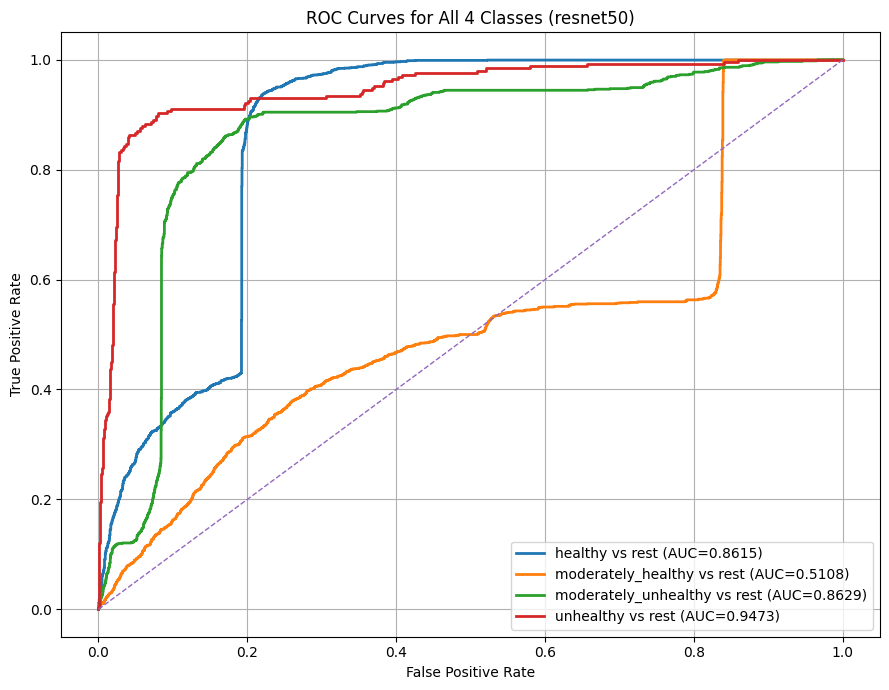


Saved ROC plot to: /home/ehr/Desktop/anupama/plant/training_runs/roc_all_4_stages_resnet50.png
Saved AUC summary to: /home/ehr/Desktop/anupama/plant/training_runs/auc_all_4_stages_resnet50.json

AUC Summary:
healthy                  : 0.8615
moderately_healthy       : 0.5108
moderately_unhealthy     : 0.8629
unhealthy                : 0.9473


In [15]:
# ============================================================
# FULL STANDALONE ROC + AUC CODE FOR ALL 4 BINARY STAGES
#
# Stages:
#   1. healthy vs rest
#   2. moderately_healthy vs rest
#   3. moderately_unhealthy vs rest
#   4. unhealthy vs rest
#
# IMPORTANT:
# In your training setup:
#   class 0 = target class
#   class 1 = rest
#
# For ROC/AUC below, we use probability of class 0
# and explicitly set pos_label=0
# ============================================================

import json
from pathlib import Path
from typing import List, Tuple

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")

# These should match your saved stage folders
STAGE_CONFIGS = [
    {
        "stage_name": "stage1_healthy_vs_rest",
        "target_class": "healthy",
        "bin_class_names": ["healthy", "rest"],
    },
    {
        "stage_name": "stage1_modhealthy_vs_rest",
        "target_class": "moderately_healthy",
        "bin_class_names": ["moderately_healthy", "rest"],
    },
    {
        "stage_name": "stage1_modunhealthy_vs_rest",
        "target_class": "moderately_unhealthy",
        "bin_class_names": ["moderately_unhealthy", "rest"],
    },
    {
        "stage_name": "stage1_unhealthy_vs_rest",
        "target_class": "unhealthy",
        "bin_class_names": ["unhealthy", "rest"],
    },
]

MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]

# ============================================================
# MULTI CLASS SOURCE LABELS
# ============================================================

MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

# ============================================================
# CONFIG
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

# Choose one model to compare ROC across all 4 classes
# Change this to: "resnet18", "resnet34", "resnet50", or "efficientnet_b0"
MODEL_TO_EVALUATE = "resnet50"

# Save output plot and auc json
OUTPUT_PLOT_PATH = OUT_ROOT / f"roc_all_4_stages_{MODEL_TO_EVALUATE}.png"
OUTPUT_AUC_JSON = OUT_ROOT / f"auc_all_4_stages_{MODEL_TO_EVALUATE}.json"

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# ============================================================
# DATASET
# ============================================================

class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, target_class: str, transform=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.target_class = target_class
        self.transform = transform

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []

        for cls_name in MULTI_CLASS_NAMES:
            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    # IMPORTANT:
                    # label 0 = target class
                    # label 1 = rest
                    y = 0 if cls_name == self.target_class else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

# ============================================================
# MODEL BUILDER
# ============================================================

def build_model(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet34":
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        model = resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model

    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

# ============================================================
# PROBABILITY EVALUATION
# ============================================================

@torch.no_grad()
def collect_labels_and_probs(model, loader, device):
    model.eval()

    all_y = []
    all_prob_class0 = []
    all_prob_class1 = []
    all_pred = []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_y.append(y.detach().cpu().numpy())
        all_prob_class0.append(probs[:, 0].detach().cpu().numpy())
        all_prob_class1.append(probs[:, 1].detach().cpu().numpy())
        all_pred.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    prob_class0 = np.concatenate(all_prob_class0, axis=0)
    prob_class1 = np.concatenate(all_prob_class1, axis=0)
    y_pred = np.concatenate(all_pred, axis=0)

    return y_true, y_pred, prob_class0, prob_class1

# ============================================================
# MAIN
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Evaluating model:", MODEL_TO_EVALUATE)

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

roc_results = []
auc_summary = {}

plt.figure(figsize=(9, 7))

for cfg in STAGE_CONFIGS:
    stage_name = cfg["stage_name"]
    target_class = cfg["target_class"]

    print("\n" + "=" * 70)
    print(f"Stage: {stage_name}")
    print(f"Target class: {target_class}")
    print("=" * 70)

    ckpt_path = OUT_ROOT / stage_name / MODEL_TO_EVALUATE / "best_model.pt"

    # If your folders are named without model subfolder, use this instead:
    # ckpt_path = OUT_ROOT / f"{stage_name}_{MODEL_TO_EVALUATE}" / "best_model.pt"

    # Try both patterns safely
    if not ckpt_path.exists():
        alt_ckpt_path = OUT_ROOT / f"{stage_name}_{MODEL_TO_EVALUATE}" / "best_model.pt"
        if alt_ckpt_path.exists():
            ckpt_path = alt_ckpt_path
        else:
            print(f"Checkpoint not found for stage {stage_name}")
            print("Tried:")
            print(" ", ckpt_path)
            print(" ", alt_ckpt_path)
            continue

    print("Checkpoint:", ckpt_path)

    # Build test dataset for this target class
    test_ds = BinaryTileFolderDataset(
        TILES_ROOT,
        split="test",
        target_class=target_class,
        transform=test_tf
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

    # Load checkpoint
    checkpoint = torch.load(ckpt_path, map_location=device)

    model_name_in_ckpt = checkpoint.get("model", MODEL_TO_EVALUATE)
    model = build_model(model_name_in_ckpt, num_classes=2, pretrained=False).to(device)

    if "model_state" in checkpoint:
        model.load_state_dict(checkpoint["model_state"])
    elif "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    elif "state_dict" in checkpoint:
        model.load_state_dict(checkpoint["state_dict"])
    else:
        raise KeyError(f"No model state found in checkpoint: {ckpt_path}")

    # Collect labels and probabilities
    y_true, y_pred, prob_class0, prob_class1 = collect_labels_and_probs(model, test_loader, device)

    # IMPORTANT:
    # Your target class is label 0
    # So ROC must be computed using:
    #   y_true with pos_label=0
    #   probability of class 0
    fpr, tpr, thresholds = roc_curve(y_true, prob_class0, pos_label=0)
    auc_value = roc_auc_score(y_true, prob_class0)

    # NOTE:
    # roc_auc_score by default assumes larger score means class 1.
    # Since class 0 is your target, the more correct version is:
    auc_value = roc_auc_score((y_true == 0).astype(int), prob_class0)

    print(f"AUC for {target_class} vs rest: {auc_value:.4f}")

    # Plot ROC
    plt.plot(fpr, tpr, linewidth=2, label=f"{target_class} vs rest (AUC={auc_value:.4f})")

    roc_results.append({
        "stage_name": stage_name,
        "target_class": target_class,
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
        "auc": float(auc_value),
    })

    auc_summary[target_class] = float(auc_value)

# Random line
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curves for All 4 Classes ({MODEL_TO_EVALUATE})")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig(OUTPUT_PLOT_PATH, dpi=300)
plt.show()

# Save AUC summary
OUTPUT_AUC_JSON.write_text(json.dumps(auc_summary, indent=2))

print("\nSaved ROC plot to:", OUTPUT_PLOT_PATH)
print("Saved AUC summary to:", OUTPUT_AUC_JSON)

print("\nAUC Summary:")
for cls_name, auc_val in auc_summary.items():
    print(f"{cls_name:25s}: {auc_val:.4f}")

Device: cuda

##########################################################################################
Evaluating model: resnet18
##########################################################################################

Stage: stage1_healthy_vs_rest
Target class: healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet18/best_model.pt
AUC for healthy vs rest: 0.9358

Stage: stage1_modhealthy_vs_rest
Target class: moderately_healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet18/best_model.pt
AUC for moderately_healthy vs rest: 0.4980

Stage: stage1_modunhealthy_vs_rest
Target class: moderately_unhealthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_resnet18/best_model.pt
AUC for moderately_unhealthy vs rest: 0.8050

Stage: stage1_unhealthy_vs_rest
Target class: unhealthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet

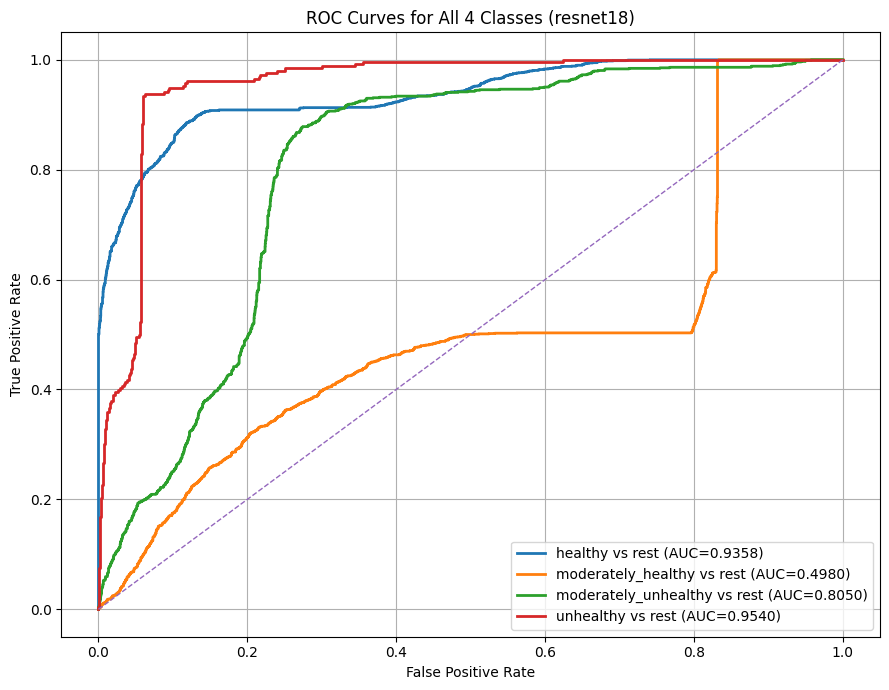


Saved ROC plot to: /home/ehr/Desktop/anupama/plant/training_runs/roc_all_4_stages_resnet18.png
Saved AUC summary to: /home/ehr/Desktop/anupama/plant/training_runs/auc_all_4_stages_resnet18.json

AUC Summary:
healthy                  : 0.9358
moderately_healthy       : 0.4980
moderately_unhealthy     : 0.8050
unhealthy                : 0.9540

##########################################################################################
Evaluating model: resnet34
##########################################################################################

Stage: stage1_healthy_vs_rest
Target class: healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet34/best_model.pt
AUC for healthy vs rest: 0.9340

Stage: stage1_modhealthy_vs_rest
Target class: moderately_healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet34/best_model.pt
AUC for moderately_healthy vs rest: 0.7323

Stage: stage1_modunhealthy_vs_rest
Tar

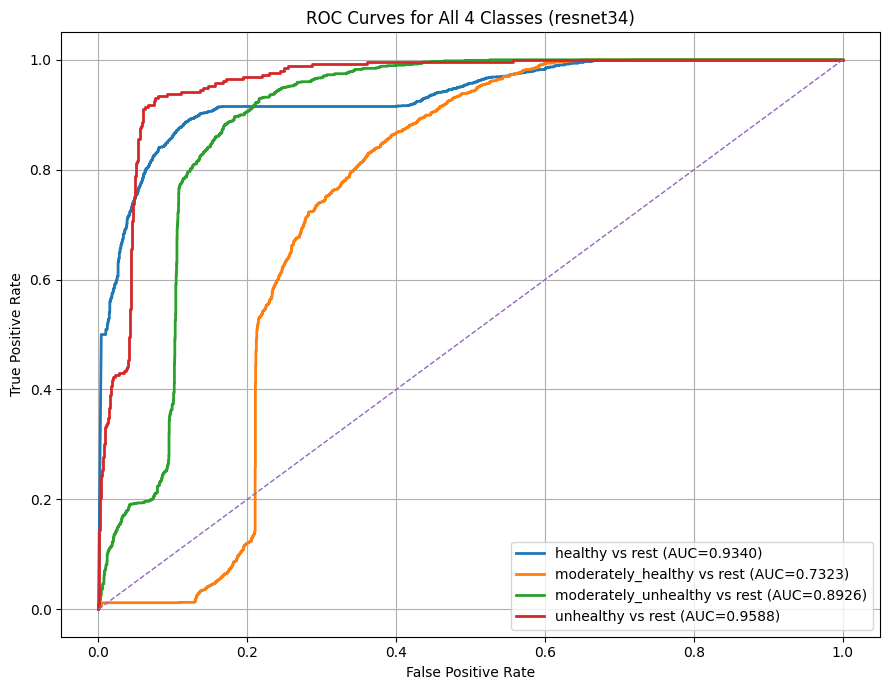


Saved ROC plot to: /home/ehr/Desktop/anupama/plant/training_runs/roc_all_4_stages_resnet34.png
Saved AUC summary to: /home/ehr/Desktop/anupama/plant/training_runs/auc_all_4_stages_resnet34.json

AUC Summary:
healthy                  : 0.9340
moderately_healthy       : 0.7323
moderately_unhealthy     : 0.8926
unhealthy                : 0.9588

##########################################################################################
Evaluating model: resnet50
##########################################################################################

Stage: stage1_healthy_vs_rest
Target class: healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet50/best_model.pt
AUC for healthy vs rest: 0.8615

Stage: stage1_modhealthy_vs_rest
Target class: moderately_healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet50/best_model.pt
AUC for moderately_healthy vs rest: 0.5108

Stage: stage1_modunhealthy_vs_rest
Tar

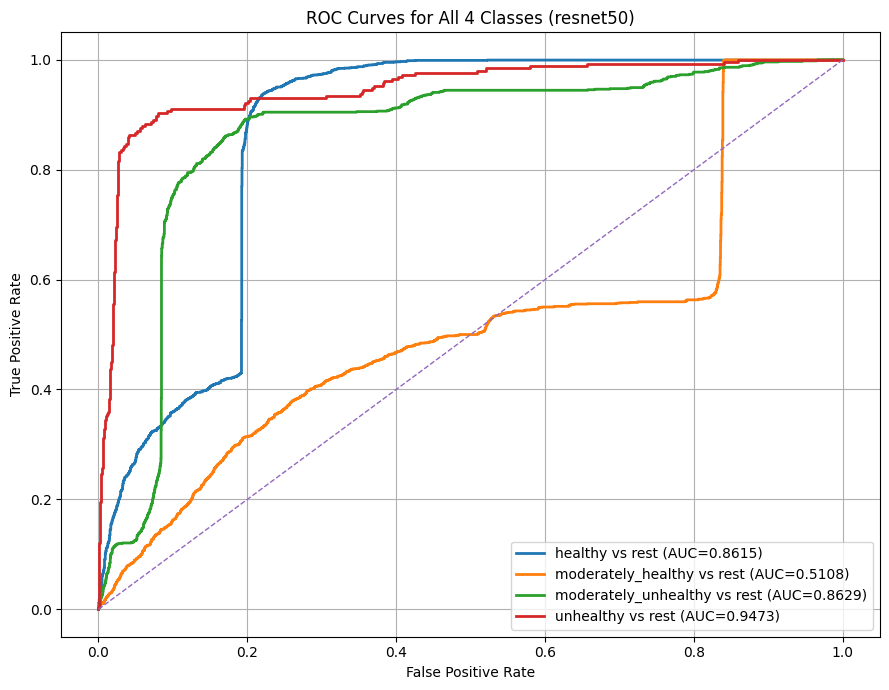


Saved ROC plot to: /home/ehr/Desktop/anupama/plant/training_runs/roc_all_4_stages_resnet50.png
Saved AUC summary to: /home/ehr/Desktop/anupama/plant/training_runs/auc_all_4_stages_resnet50.json

AUC Summary:
healthy                  : 0.8615
moderately_healthy       : 0.5108
moderately_unhealthy     : 0.8629
unhealthy                : 0.9473

##########################################################################################
Evaluating model: efficientnet_b0
##########################################################################################

Stage: stage1_healthy_vs_rest
Target class: healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_efficientnet_b0/best_model.pt
AUC for healthy vs rest: 0.9141

Stage: stage1_modhealthy_vs_rest
Target class: moderately_healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_efficientnet_b0/best_model.pt
AUC for moderately_healthy vs rest: 0.7649

Stage: stage1_mod

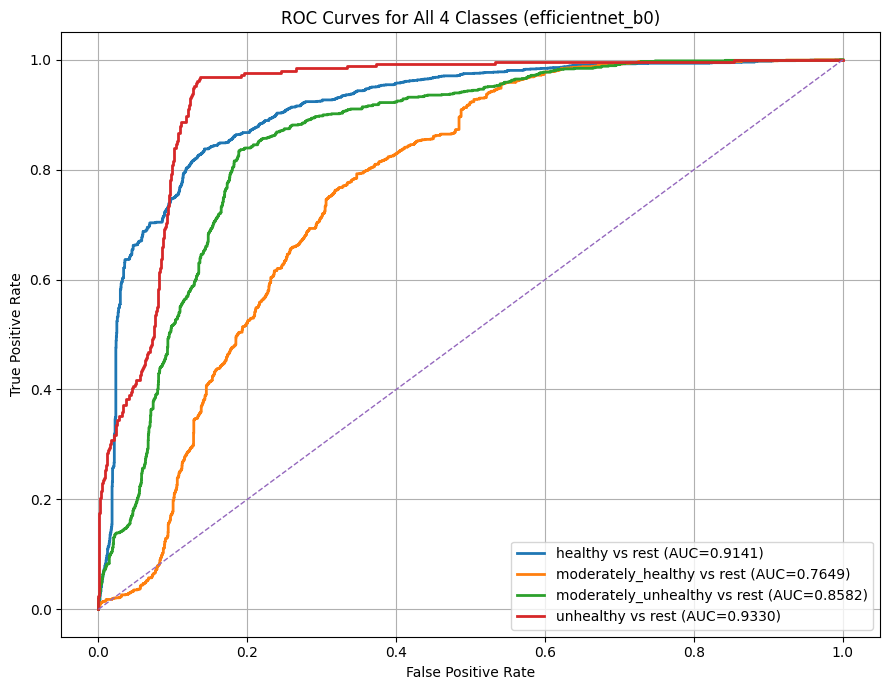


Saved ROC plot to: /home/ehr/Desktop/anupama/plant/training_runs/roc_all_4_stages_efficientnet_b0.png
Saved AUC summary to: /home/ehr/Desktop/anupama/plant/training_runs/auc_all_4_stages_efficientnet_b0.json

AUC Summary:
healthy                  : 0.9141
moderately_healthy       : 0.7649
moderately_unhealthy     : 0.8582
unhealthy                : 0.9330

##########################################################################################
Finished evaluating all models
Combined AUC summary saved to: /home/ehr/Desktop/anupama/plant/training_runs/auc_all_models_all_4_stages.json
##########################################################################################

Final Combined AUC Summary:

Model: resnet18
  healthy                  : 0.9358
  moderately_healthy       : 0.4980
  moderately_unhealthy     : 0.8050
  unhealthy                : 0.9540

Model: resnet34
  healthy                  : 0.9340
  moderately_healthy       : 0.7323
  moderately_unhealthy     : 0.8926
  

In [1]:
# ============================================================
# FULL STANDALONE ROC + AUC CODE FOR ALL 4 BINARY STAGES
# FOR ALL MODELS:
#   resnet18, resnet34, resnet50, efficientnet_b0
#
# Stages:
#   1. healthy vs rest
#   2. moderately_healthy vs rest
#   3. moderately_unhealthy vs rest
#   4. unhealthy vs rest
#
# IMPORTANT:
# In your training setup:
#   class 0 = target class
#   class 1 = rest
#
# For ROC/AUC below, we use probability of class 0
# and explicitly set pos_label=0
# ============================================================

import json
from pathlib import Path
from typing import List, Tuple

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    resnet18, resnet34, resnet50,
    ResNet18_Weights, ResNet34_Weights, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights
)

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ============================================================
# PATHS
# ============================================================

TILES_ROOT = Path("/home/ehr/Desktop/anupama/plant/class_tiles")
OUT_ROOT = Path("/home/ehr/Desktop/anupama/plant/training_runs")

# These should match your saved stage folders
STAGE_CONFIGS = [
    {
        "stage_name": "stage1_healthy_vs_rest",
        "target_class": "healthy",
        "bin_class_names": ["healthy", "rest"],
    },
    {
        "stage_name": "stage1_modhealthy_vs_rest",
        "target_class": "moderately_healthy",
        "bin_class_names": ["moderately_healthy", "rest"],
    },
    {
        "stage_name": "stage1_modunhealthy_vs_rest",
        "target_class": "moderately_unhealthy",
        "bin_class_names": ["moderately_unhealthy", "rest"],
    },
    {
        "stage_name": "stage1_unhealthy_vs_rest",
        "target_class": "unhealthy",
        "bin_class_names": ["unhealthy", "rest"],
    },
]

# Evaluate all models
MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "efficientnet_b0"]

# ============================================================
# MULTI CLASS SOURCE LABELS
# ============================================================

MULTI_CLASS_NAMES = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy",
]

# ============================================================
# CONFIG
# ============================================================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 4
SEED = 42

# ============================================================
# HELPERS
# ============================================================

def set_seed(seed: int = 42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def is_image_file(p: Path) -> bool:
    return p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# ============================================================
# DATASET
# ============================================================

class BinaryTileFolderDataset(Dataset):
    def __init__(self, tiles_root: Path, split: str, target_class: str, transform=None):
        self.tiles_root = Path(tiles_root)
        self.split = split
        self.target_class = target_class
        self.transform = transform

        split_dir = self.tiles_root / split
        if not split_dir.exists():
            raise FileNotFoundError(f"Split folder not found: {split_dir}")

        items: List[Tuple[Path, int]] = []

        for cls_name in MULTI_CLASS_NAMES:
            cls_dir = split_dir / cls_name
            if not cls_dir.exists():
                print(f"WARNING: class folder missing: {cls_dir}")
                continue

            for img_path in sorted(cls_dir.rglob("*")):
                if img_path.is_file() and is_image_file(img_path):
                    # label 0 = target class
                    # label 1 = rest
                    y = 0 if cls_name == self.target_class else 1
                    items.append((img_path, y))

        if len(items) == 0:
            raise RuntimeError(f"No images found for split '{split}' under: {split_dir}")

        self.items = items

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx: int):
        img_path, label = self.items[idx]
        with Image.open(img_path) as im:
            im = im.convert("RGB")
            if self.transform is not None:
                im = self.transform(im)
        return im, label

# ============================================================
# MODEL BUILDER
# ============================================================

def build_model(model_name: str, num_classes: int = 2, pretrained: bool = False) -> nn.Module:
    model_name = model_name.lower().strip()

    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        model = resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet34":
        weights = ResNet34_Weights.DEFAULT if pretrained else None
        model = resnet34(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "resnet50":
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model

    if model_name == "efficientnet_b0":
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return model

    raise ValueError("Unknown model. Use resnet18, resnet34, resnet50, efficientnet_b0")

# ============================================================
# PROBABILITY EVALUATION
# ============================================================

@torch.no_grad()
def collect_labels_and_probs(model, loader, device):
    model.eval()

    all_y = []
    all_prob_class0 = []
    all_prob_class1 = []
    all_pred = []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        logits = model(x)
        probs = torch.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        all_y.append(y.detach().cpu().numpy())
        all_prob_class0.append(probs[:, 0].detach().cpu().numpy())
        all_prob_class1.append(probs[:, 1].detach().cpu().numpy())
        all_pred.append(preds.detach().cpu().numpy())

    y_true = np.concatenate(all_y, axis=0)
    prob_class0 = np.concatenate(all_prob_class0, axis=0)
    prob_class1 = np.concatenate(all_prob_class1, axis=0)
    y_pred = np.concatenate(all_pred, axis=0)

    return y_true, y_pred, prob_class0, prob_class1

# ============================================================
# MAIN
# ============================================================

set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

test_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Optional: cache test datasets so we do not rebuild them for each model
test_dataset_cache = {}
for cfg in STAGE_CONFIGS:
    target_class = cfg["target_class"]
    test_dataset_cache[target_class] = BinaryTileFolderDataset(
        TILES_ROOT,
        split="test",
        target_class=target_class,
        transform=test_tf
    )

all_models_auc_summary = {}

for model_name in MODEL_NAMES:
    print("\n" + "#" * 90)
    print(f"Evaluating model: {model_name}")
    print("#" * 90)

    roc_results = []
    auc_summary = {}

    output_plot_path = OUT_ROOT / f"roc_all_4_stages_{model_name}.png"
    output_auc_json = OUT_ROOT / f"auc_all_4_stages_{model_name}.json"

    plt.figure(figsize=(9, 7))

    for cfg in STAGE_CONFIGS:
        stage_name = cfg["stage_name"]
        target_class = cfg["target_class"]

        print("\n" + "=" * 70)
        print(f"Stage: {stage_name}")
        print(f"Target class: {target_class}")
        print("=" * 70)

        ckpt_path = OUT_ROOT / stage_name / model_name / "best_model.pt"

        # Alternate folder pattern
        if not ckpt_path.exists():
            alt_ckpt_path = OUT_ROOT / f"{stage_name}_{model_name}" / "best_model.pt"
            if alt_ckpt_path.exists():
                ckpt_path = alt_ckpt_path
            else:
                print(f"Checkpoint not found for model={model_name}, stage={stage_name}")
                print("Tried:")
                print(" ", ckpt_path)
                print(" ", alt_ckpt_path)
                continue

        print("Checkpoint:", ckpt_path)

        test_ds = test_dataset_cache[target_class]

        test_loader = DataLoader(
            test_ds,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=(device.type == "cuda")
        )

        checkpoint = torch.load(ckpt_path, map_location=device)

        model_name_in_ckpt = checkpoint.get("model", model_name)
        model = build_model(model_name_in_ckpt, num_classes=2, pretrained=False).to(device)

        if "model_state" in checkpoint:
            model.load_state_dict(checkpoint["model_state"])
        elif "model_state_dict" in checkpoint:
            model.load_state_dict(checkpoint["model_state_dict"])
        elif "state_dict" in checkpoint:
            model.load_state_dict(checkpoint["state_dict"])
        else:
            raise KeyError(f"No model state found in checkpoint: {ckpt_path}")

        y_true, y_pred, prob_class0, prob_class1 = collect_labels_and_probs(model, test_loader, device)

        # target class is label 0
        fpr, tpr, thresholds = roc_curve(y_true, prob_class0, pos_label=0)

        # proper AUC for target class = label 0
        auc_value = roc_auc_score((y_true == 0).astype(int), prob_class0)

        print(f"AUC for {target_class} vs rest: {auc_value:.4f}")

        plt.plot(
            fpr, tpr,
            linewidth=2,
            label=f"{target_class} vs rest (AUC={auc_value:.4f})"
        )

        roc_results.append({
            "model_name": model_name,
            "stage_name": stage_name,
            "target_class": target_class,
            "fpr": fpr.tolist(),
            "tpr": tpr.tolist(),
            "auc": float(auc_value),
        })

        auc_summary[target_class] = float(auc_value)

    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curves for All 4 Classes ({model_name})")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(output_plot_path, dpi=300)
    plt.show()
    plt.close()

    output_auc_json.write_text(json.dumps(auc_summary, indent=2))

    all_models_auc_summary[model_name] = auc_summary

    print("\nSaved ROC plot to:", output_plot_path)
    print("Saved AUC summary to:", output_auc_json)

    print("\nAUC Summary:")
    for cls_name, auc_val in auc_summary.items():
        print(f"{cls_name:25s}: {auc_val:.4f}")

# ============================================================
# OPTIONAL: SAVE COMBINED SUMMARY FOR ALL MODELS
# ============================================================

combined_auc_json = OUT_ROOT / "auc_all_models_all_4_stages.json"
combined_auc_json.write_text(json.dumps(all_models_auc_summary, indent=2))

print("\n" + "#" * 90)
print("Finished evaluating all models")
print("Combined AUC summary saved to:", combined_auc_json)
print("#" * 90)

print("\nFinal Combined AUC Summary:")
for model_name, summary in all_models_auc_summary.items():
    print(f"\nModel: {model_name}")
    for cls_name, auc_val in summary.items():
        print(f"  {cls_name:25s}: {auc_val:.4f}")

Device: cuda
Found classes: ['healthy', 'moderately_healthy', 'moderately_unhealthy', 'unhealthy']
class_to_idx: {'healthy': 0, 'moderately_healthy': 1, 'moderately_unhealthy': 2, 'unhealthy': 3}

Evaluating: healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet50/best_model.pt
Using architecture: resnet50
AUC for healthy vs rest: 0.6298

Evaluating: moderately_healthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet50/best_model.pt
Using architecture: resnet50
AUC for moderately_healthy vs rest: 0.4379

Evaluating: moderately_unhealthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_resnet50/best_model.pt
Using architecture: resnet50
AUC for moderately_unhealthy vs rest: 0.5860

Evaluating: unhealthy
Checkpoint: /home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet50/best_model.pt
Using architecture: resnet50
AUC for unhealthy vs rest: 0.710

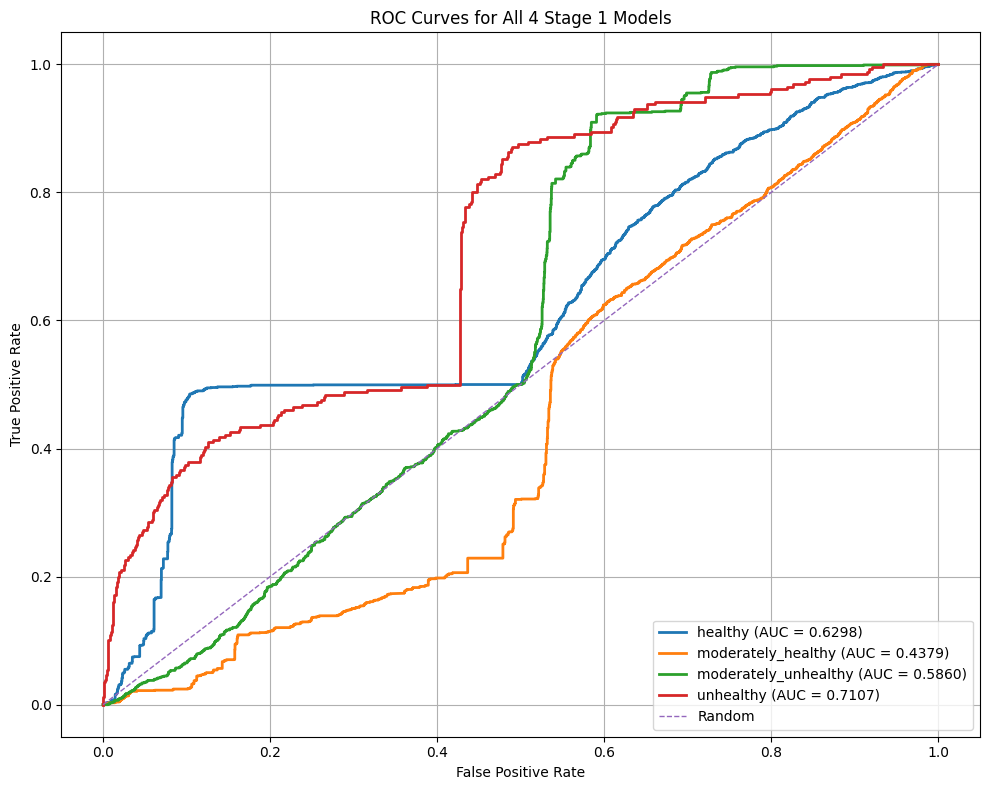


Saved ROC plot to: /home/ehr/Desktop/anupama/plant/all_stage1_roc_curves.png

AUC Summary:
healthy: 0.6298
moderately_healthy: 0.4379
moderately_unhealthy: 0.5860
unhealthy: 0.7107


In [4]:
import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

# ==========================================
# CONFIG
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
test_root = "/home/ehr/Desktop/anupama/plant/class_tiles/test"
batch_size = 32

stage_checkpoints = {
    "healthy": "/home/ehr/Desktop/anupama/plant/training_runs/stage1_healthy_vs_rest_resnet50/best_model.pt",
    "moderately_healthy": "/home/ehr/Desktop/anupama/plant/training_runs/stage1_modhealthy_vs_rest_resnet50/best_model.pt",
    "moderately_unhealthy": "/home/ehr/Desktop/anupama/plant/training_runs/stage1_modunhealthy_vs_rest_resnet50/best_model.pt",
    "unhealthy": "/home/ehr/Desktop/anupama/plant/training_runs/stage1_unhealthy_vs_rest_resnet50/best_model.pt",
}

all_expected_classes = [
    "healthy",
    "moderately_healthy",
    "moderately_unhealthy",
    "unhealthy",
    "severely_unhealthy"
]

# ==========================================
# TRANSFORMS
# ==========================================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# ==========================================
# CHECK TEST FOLDERS
# ==========================================
for cls in all_expected_classes:
    cls_path = os.path.join(test_root, cls)
    if not os.path.isdir(cls_path):
        print(f"WARNING: class folder missing: {cls_path}")

# ==========================================
# DATASET AND LOADER
# ==========================================
dataset = datasets.ImageFolder(test_root, transform=transform)
loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

print("Device:", device)
print("Found classes:", dataset.classes)
print("class_to_idx:", dataset.class_to_idx)

# ==========================================
# MODEL BUILDER
# ==========================================
def build_model(model_name, num_classes=2):
    model_name = str(model_name).lower()

    if model_name == "resnet18":
        model = models.resnet18(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "resnet50":
        model = models.resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "efficientnet_b0":
        model = models.efficientnet_b0(weights=None)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)

    else:
        raise ValueError(f"Unsupported model_name: {model_name}")

    return model

# ==========================================
# CHECKPOINT LOADER
# Supports:
#   ckpt["model_state"]
#   ckpt["model_state_dict"]
#   raw state_dict
# Also auto-detects architecture from ckpt["model"]
# ==========================================
def load_checkpoint_model(ckpt_path, fallback_model_name="resnet50"):
    ckpt = torch.load(ckpt_path, map_location=device)

    saved_model_name = None
    if isinstance(ckpt, dict) and "model" in ckpt:
        saved_model_name = ckpt["model"]

    model_name = saved_model_name if saved_model_name is not None else fallback_model_name
    print(f"Using architecture: {model_name}")

    model = build_model(model_name, num_classes=2)

    if isinstance(ckpt, dict):
        if "model_state" in ckpt:
            state_dict = ckpt["model_state"]
        elif "model_state_dict" in ckpt:
            state_dict = ckpt["model_state_dict"]
        else:
            state_dict = ckpt
    else:
        state_dict = ckpt

    model.load_state_dict(state_dict)
    model = model.to(device)
    model.eval()
    return model

# ==========================================
# ROC COMPUTATION
# IMPORTANT:
# your labels are:
#   0 = target class
#   1 = rest
#
# For sklearn ROC:
#   y_true should be 1 for target class, 0 otherwise
#   y_score should be probability of model class 0
# ==========================================
roc_results = {}

with torch.no_grad():
    for target_class, ckpt_path in stage_checkpoints.items():
        if target_class not in dataset.class_to_idx:
            print(f"Skipping {target_class}: class not found in dataset")
            continue

        print("\n" + "=" * 70)
        print(f"Evaluating: {target_class}")
        print(f"Checkpoint: {ckpt_path}")

        model = load_checkpoint_model(ckpt_path, fallback_model_name="resnet50")
        target_idx = dataset.class_to_idx[target_class]

        y_true = []
        y_score = []

        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            probs = torch.softmax(logits, dim=1)

            # In your binary training setup:
            # class 0 = target class
            target_probs = probs[:, 0]

            # Convert folder labels into binary truth:
            # 1 = target class, 0 = rest
            binary_truth = (labels == target_idx).long()

            y_true.extend(binary_truth.cpu().numpy())
            y_score.extend(target_probs.cpu().numpy())

        y_true = np.array(y_true)
        y_score = np.array(y_score)

        if len(np.unique(y_true)) < 2:
            print(f"Skipping ROC for {target_class}: only one class present")
            continue

        fpr, tpr, _ = roc_curve(y_true, y_score)
        roc_auc = auc(fpr, tpr)

        roc_results[target_class] = {
            "fpr": fpr,
            "tpr": tpr,
            "auc": roc_auc
        }

        print(f"AUC for {target_class} vs rest: {roc_auc:.4f}")

# ==========================================
# PLOT ALL ROC CURVES
# ==========================================
plt.figure(figsize=(10, 8))

for class_name, result in roc_results.items():
    plt.plot(
        result["fpr"],
        result["tpr"],
        linewidth=2,
        label=f"{class_name} (AUC = {result['auc']:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for All 4 Stage 1 Models")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()

save_path = "/home/ehr/Desktop/anupama/plant/all_stage1_roc_curves.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("\n" + "=" * 70)
print(f"Saved ROC plot to: {save_path}")

# ==========================================
# OPTIONAL: print final AUC summary
# ==========================================
print("\nAUC Summary:")
for class_name, result in roc_results.items():
    print(f"{class_name}: {result['auc']:.4f}")